# The Neural Network Zoo, Part 2: Scientific Machine Learning and Modern Architectures

> **Who is this for:** a learner who already knows what an MLP, a CNN and a training loop are, and now wants a guided tour of the *other* network families: networks that respect physics, networks that learn whole solvers, networks that are a picture or a 3D scene, networks that respect symmetry, and the modern sequence and vision designs. Also useful for BS/MS AI students revising for exams and interviews.
>
> **What you will learn**
> - **Scientific machine learning**: data-driven vs physics-based vs hybrid models, and where neural networks meet differential equations
> - **Physics-informed neural networks (PINNs)** in depth, with three PyTorch demos: a damped oscillator from sparse noisy data (plain NN vs PINN), the heat equation solved with *no data at all*, and an **inverse problem** that learns an unknown damping coefficient
> - **Neural operators**: **DeepONet** (learning the antiderivative operator) and the **Fourier neural operator** (a spectral convolution layer with `torch.fft`, tested at a resolution it never saw)
> - **Hamiltonian neural networks** (energy-conserving dynamics vs a plain NN that drifts), Lagrangian networks, neural ODEs and universal differential equations
> - **Kolmogorov-Arnold networks (KAN)** with B-spline edges, and how to "read off" a formula
> - **Implicit neural representations**: **SIREN** vs a ReLU MLP vs Fourier features on an image; **NeRF** volume rendering on one ray; Gaussian splatting
> - **Equivariant and geometric networks**: Deep Sets / PointNet, a rotation-equivariant group convolution, and an E(3)-equivariant GNN layer for molecules
> - **Sequence models beyond RNNs**: TCN / WaveNet (dilated causal convolutions), **state-space models / Mamba** (recurrence = convolution, and the selective idea), linear attention / RWKV, xLSTM
> - **Vision lineage** from LeNet to ConvNeXt, a tiny **U-Net** with shapes, and detection families
> - **Conditional computation**: Mixture of Experts, early-exit networks, sparse networks and the lottery ticket idea
> - **World models, JEPA and diffusion transformers** (brief), and a **master table of all architectures** in Part 1 and Part 2
>
> **Prerequisites:** [`00_start_here_pytorch_from_zero.ipynb`](00_start_here_pytorch_from_zero.ipynb) (tensors, autograd, training loops), [`01_neural_network_fundamentals.ipynb`](01_neural_network_fundamentals.ipynb), [`03_cnn.ipynb`](03_cnn.ipynb), and for the maths of derivatives and ODE solvers [`../14_Mathematics/02_calculus.ipynb`](../14_Mathematics/02_calculus.ipynb) and [`../14_Mathematics/09_numerical_methods.ipynb`](../14_Mathematics/09_numerical_methods.ipynb). Part 1 of the zoo is [`23_neural_network_zoo_classic_and_alternative_architectures.ipynb`](23_neural_network_zoo_classic_and_alternative_architectures.ipynb).
>
> **Time needed:** about 3 to 4 hours to read and experiment; the notebook itself runs in about 2 to 3 minutes.
>
> **Runs on:** CPU only, no GPU, no API key, no internet. Uses numpy, matplotlib, pandas, scikit-learn (for a small built-in dataset) and PyTorch (CPU).

## Explained simply

Most networks you have met so far learn **only from examples**: show a CNN many cat photos and it learns cats. This notebook is about networks that are built with **extra knowledge baked in**.

- Some networks know the **laws of physics**. A PINN is told "whatever you predict must obey this equation", so it needs far fewer measurements.
- Some networks learn a **whole solver** at once. Instead of "the answer for this one starting shape", a neural operator learns "the rule that turns any starting shape into its answer".
- Some networks **are** the data. A SIREN or NeRF stores one image or one 3D scene inside its weights: you ask "what colour is at this point?" and it answers.
- Some networks know **symmetry**. If you rotate a molecule, its energy does not change; an equivariant network gets that right automatically instead of having to learn it from data.
- Some networks are simply **newer designs** for sequences and images, such as Mamba, WaveNet, U-Net and ConvNeXt.

Everyday picture: a student who memorised a thousand past exam answers (a plain network) vs a student who also learned the formula sheet (a physics-informed network). The second student needs fewer examples and makes fewer silly mistakes on new questions, but only if the formula sheet is correct.

For every family we follow the same pattern: **what it is, a simple analogy, how it works (with the key maths in words and LaTeX), a small runnable demo, where it is used today, and its limits.**

## Contents

0. Setup
1. Scientific machine learning: the big picture
2. Physics-informed neural networks (PINNs)
3. Neural operators: DeepONet and the Fourier neural operator
4. Physics-structured dynamics: neural ODEs, Hamiltonian and Lagrangian networks, universal differential equations
5. Kolmogorov-Arnold networks (KAN)
6. Implicit neural representations: SIREN, Fourier features, NeRF, Gaussian splatting
7. Equivariant and geometric networks
8. Sequence architectures beyond RNNs: TCN/WaveNet, state-space models/Mamba, linear attention/RWKV, xLSTM
9. Vision architecture lineage, U-Net and detection families
10. Conditional computation and efficiency: MoE, early exit, sparse networks
11. World models, JEPA and diffusion transformers
12. Master table of all architectures
13. Recap, interview questions, further reading

## 0. Setup

We use PyTorch on the CPU because several demos need **autograd**: automatic computation of derivatives. In a PINN we take derivatives of the network's *output with respect to its input* (for example $du/dt$), not only with respect to the weights. We fix every random seed so your numbers match the text, and limit PyTorch to 4 CPU threads.

In [1]:
import time, math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 0
def seed_all(s=SEED):
    # fix numpy and torch random number generators
    np.random.seed(s)
    torch.manual_seed(s)

seed_all()
torch.set_num_threads(4)
plt.rcParams["figure.figsize"] = (9, 3)
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.width", 140)

def grad(y, x):
    # dy/dx with autograd. create_graph=True keeps the graph so we can take a
    # second derivative and also backpropagate through the derivative itself.
    return torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y), create_graph=True)[0]

def mlp(n_in, n_out, width=32, depth=3, act=nn.Tanh):
    # a plain fully connected network: n_in -> width -> ... -> n_out
    layers, d = [], n_in
    for _ in range(depth):
        layers += [nn.Linear(d, width), act()]
        d = width
    layers.append(nn.Linear(d, n_out))
    return nn.Sequential(*layers)

def n_params(model):
    return sum(p.numel() for p in model.parameters())

T_START = time.time()
print("torch", torch.__version__, "| numpy", np.__version__)

torch 2.15.0+cpu | numpy 2.5.4


**Warm-up: derivatives of a network's output with respect to its input.** This one idea powers PINNs and Hamiltonian networks. Below, `y = sin(x)`; autograd gives $dy/dx$ and $d^2y/dx^2$, and we check them against the known answers $\cos x$ and $-\sin x$. Autograd is exact (up to floating point), unlike finite differences.

In [2]:
x = torch.linspace(0, 3, 5).reshape(-1, 1).requires_grad_(True)   # inputs we differentiate w.r.t.
y = torch.sin(x)
dy = grad(y, x)          # first derivative
d2y = grad(dy, x)        # second derivative (possible because create_graph=True)
xs = x.detach().numpy().ravel()
print(pd.DataFrame({"x": xs, "autograd dy": dy.detach().numpy().ravel(), "cos(x)": np.cos(xs),
                    "autograd d2y": d2y.detach().numpy().ravel(), "-sin(x)": -np.sin(xs)}).round(5))

      x  autograd dy   cos(x)  autograd d2y  -sin(x)
0  0.00      1.00000  1.00000      -0.00000 -0.00000
1  0.75      0.73169  0.73169      -0.68164 -0.68164
2  1.50      0.07074  0.07074      -0.99750 -0.99750
3  2.25     -0.62817 -0.62817      -0.77807 -0.77807
4  3.00     -0.98999 -0.98999      -0.14112 -0.14112


## 1. Scientific machine learning: the big picture

**What it is.** *Scientific machine learning (SciML)* means combining machine learning with scientific knowledge, usually equations from physics, chemistry, biology or engineering. The equations are most often **differential equations**: rules that say how something changes.

**Key words (one sentence each).**
- **ODE (ordinary differential equation):** an equation for a function of *one* variable, usually time, e.g. $\frac{dx}{dt} = -x$.
- **PDE (partial differential equation):** an equation for a function of *several* variables, e.g. temperature $u(x, t)$ along a rod: $\frac{\partial u}{\partial t} = \alpha \frac{\partial^2 u}{\partial x^2}$.
- **Initial condition (IC):** the state at the start, e.g. $x(0) = 1$.
- **Boundary condition (BC):** what happens at the edges of space, e.g. the rod's ends stay at temperature 0.
- **Residual:** how badly a candidate solution breaks the equation. If you move everything to one side, $\frac{\partial u}{\partial t} - \alpha \frac{\partial^2 u}{\partial x^2}$ should be 0; whatever is left over is the residual.
- **Forward problem:** you know the equation and its parameters; find the solution.
- **Inverse problem:** you have measurements of the solution; find an unknown parameter (or term) in the equation.
- **Surrogate model:** a fast approximate model that stands in for a slow, accurate simulator.

**Three ways to model the world**

| | Physics-based (classical) | Data-driven (pure ML) | Hybrid (SciML) |
|---|---|---|---|
| What you need | the correct equations + a numerical solver | lots of data | some equations + some data |
| Strengths | accurate, explainable, extrapolates | captures effects nobody wrote down; fast once trained | needs less data, respects known laws, can fill gaps in the equations |
| Weaknesses | slow for big 3D problems; equations may be incomplete | data hungry; can break physical laws; poor extrapolation | harder to train; more design choices |
| Example | finite-element model of a bridge | a CNN predicting rain from radar images | a PINN, or a weather model with a learned correction term |

**Simple analogy.** Physics-based modelling is following a recipe exactly. Data-driven modelling is learning to cook by tasting thousands of dishes. Hybrid modelling is following the recipe but adjusting the salt based on tasting.

**Where neural networks meet differential equations**

```mermaid
flowchart LR
    DE[Differential equation<br/>du/dt = F of u] --> A[NN is the solution<br/>u approx NN of x,t<br/>PINN]
    DE --> B[NN is the solver<br/>initial state to final state<br/>DeepONet, FNO]
    DE --> C[NN is the dynamics F<br/>Neural ODE, HNN, LNN]
    DE --> D[NN is the missing term<br/>F = known + NN<br/>Universal DE]
    DE --> E[NN is a fast surrogate<br/>for a slow simulator<br/>weather, CFD]
```

| Role of the network | Family | Section |
|---|---|---|
| approximates the solution $u(x,t)$ of one problem | PINN | 2 |
| approximates the solution operator for a whole family of problems | DeepONet, FNO | 3 |
| approximates the right-hand side (the "rule of change") | Neural ODE, Hamiltonian / Lagrangian NN | 4 |
| approximates only the unknown part of a known equation | Universal differential equation | 4 |

Classical numerical solvers (Euler, Runge-Kutta, finite differences) are taught in [`../14_Mathematics/09_numerical_methods.ipynb`](../14_Mathematics/09_numerical_methods.ipynb); this notebook assumes you know roughly what they do.

## 2. Physics-informed neural networks (PINNs)

### 2.1 The idea

**What it is.** A PINN is an ordinary MLP $u_\theta(x, t)$ that takes coordinates (space, time) as input and outputs the solution value. What makes it "physics-informed" is the **loss function**: besides fitting any measurements, it is penalised whenever its output breaks the differential equation, the boundary conditions or the initial conditions (Raissi, Perdikaris and Karniadakis, 2019).

**Simple analogy.** A student solving homework with an answer checker that does not know the answers, only the rules. Each time the student's answer breaks a rule, the checker says "wrong by this much", and the student adjusts.

**How it works.**
1. Pick a network $u_\theta$ (inputs: coordinates; output: the quantity, e.g. position or temperature).
2. Pick **collocation points**: places in the domain where we *check the equation*. They need no measured value, just coordinates.
3. Use autograd to compute the derivatives the equation needs, e.g. $\partial u/\partial t$ and $\partial^2 u/\partial x^2$, at those points.
4. Add up the losses and train with gradient descent:

$$
\mathcal{L}(\theta) = \lambda_d \underbrace{\frac{1}{N_d}\sum_{i}\big(u_\theta(x_i) - u_i^{\text{obs}}\big)^2}_{\text{data loss}}
+ \lambda_r \underbrace{\frac{1}{N_r}\sum_{j}\big(\mathcal{N}[u_\theta](x_j)\big)^2}_{\text{PDE residual loss}}
+ \lambda_b \underbrace{\frac{1}{N_b}\sum_{k}\big(\mathcal{B}[u_\theta](x_k) - g_k\big)^2}_{\text{boundary / initial loss}}
$$

In words: *miss the measurements a little, break the equation a little, break the edge rules a little; make the total as small as possible.* Here $\mathcal{N}[u]$ is "the equation with everything moved to one side" (the residual), $\mathcal{B}[u]$ is the boundary/initial rule, and the $\lambda$ values are weights that balance the three parts.

```mermaid
flowchart LR
    X[coordinates x, t] --> NN[MLP u_theta]
    NN --> U[u]
    U --> AD[autograd:<br/>du/dt, d2u/dx2]
    AD --> R[PDE residual loss]
    U --> D[data loss<br/>at measured points]
    U --> B[boundary + initial loss]
    R --> L[total loss]
    D --> L
    B --> L
    L -->|backprop to theta| NN
```

**When to use it / when not to.** Good for problems with **little data but a trusted equation**, inverse problems (finding unknown parameters), irregular geometry, and when you want a smooth, differentiable solution. For routine forward problems where a classical solver exists, a classical solver is usually faster and more accurate.

### 2.2 Demo (a): damped harmonic oscillator from sparse noisy data

A mass on a spring with friction obeys

$$\ddot{x} + \mu\,\dot{x} + k\,x = 0, \qquad x(0) = 1,\ \dot{x}(0) = 0,$$

where $\dot x$ means $dx/dt$ (velocity), $\ddot x$ means $d^2x/dt^2$ (acceleration), $\mu$ is the damping (friction) and $k$ is the spring stiffness. In words: *acceleration + friction x velocity + stiffness x position = 0*. With $\mu = 0.4$ and $k = 4$ the exact solution is a decaying wave $x(t) = e^{-at}\big(\cos\omega t + \tfrac{a}{\omega}\sin\omega t\big)$ with $a = \mu/2$, $\omega = \sqrt{k - a^2}$.

The catch: we only get **12 noisy measurements, all in the first 2.5 seconds**, and we want the motion up to 6 seconds.

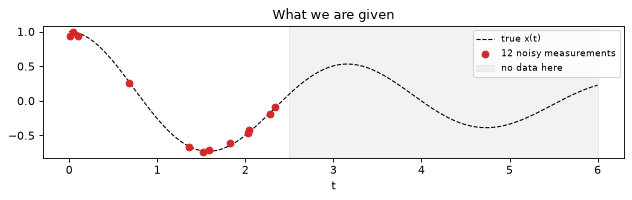

In [3]:
MU_TRUE, K = 0.4, 4.0          # damping and stiffness (mass = 1)
T_END = 6.0                    # we want the solution on [0, 6]

def oscillator_exact(t, mu=MU_TRUE, k=K):
    a = mu / 2
    w = np.sqrt(k - a**2)
    return np.exp(-a * t) * (np.cos(w * t) + a / w * np.sin(w * t))

rng = np.random.default_rng(0)
t_obs = np.sort(rng.uniform(0, 2.5, 12))                          # sparse: only early times
x_obs = oscillator_exact(t_obs) + 0.03 * rng.standard_normal(12)   # noisy measurements
t_dense = np.linspace(0, T_END, 300)

plt.figure(figsize=(8, 2.6))
plt.plot(t_dense, oscillator_exact(t_dense), "k--", lw=1, label="true x(t)")
plt.scatter(t_obs, x_obs, c="tab:red", zorder=3, label="12 noisy measurements")
plt.axvspan(2.5, T_END, color="grey", alpha=0.1, label="no data here")
plt.xlabel("t"); plt.legend(fontsize=8); plt.title("What we are given"); plt.tight_layout(); plt.show()

Now we train the **same network twice**: once with only the data loss (a plain NN), once with data + equation residual + initial conditions (a PINN). The residual is checked at 150 collocation points spread over the whole interval $[0, 6]$, including where there is no data.

trained both in 12.5 s
          RMSE where data exists [0, 2.5]  RMSE with no data (2.5, 6]
plain NN                           0.0221                      1.0542
PINN                               0.0157                      0.1544


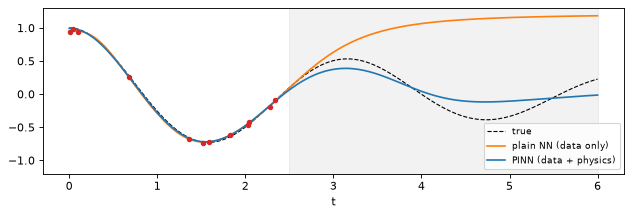

In [4]:
def train_oscillator(use_physics, steps=3000, lam_res=1e-2, seed=0):
    torch.manual_seed(seed)
    net = mlp(1, 1, width=32, depth=3)
    opt = torch.optim.Adam(net.parameters(), lr=3e-3)
    u = lambda t: net(t / T_END)                         # scale input to [0, 1]: helps training
    td = torch.tensor(t_obs, dtype=torch.float32)[:, None]
    xd = torch.tensor(x_obs, dtype=torch.float32)[:, None]
    t_col = torch.linspace(0, T_END, 150)[:, None].requires_grad_(True)  # collocation points
    t_zero = torch.zeros(1, 1, requires_grad=True)
    for step in range(steps):
        loss = ((u(td) - xd) ** 2).mean()                  # data loss
        if use_physics:
            x = u(t_col)
            xt = grad(x, t_col)                            # velocity  dx/dt
            xtt = grad(xt, t_col)                          # acceleration d2x/dt2
            residual = xtt + MU_TRUE * xt + K * x          # should be 0 everywhere
            x0 = u(t_zero); v0 = grad(x0, t_zero)
            loss_ic = (x0 - 1).pow(2).mean() + v0.pow(2).mean()   # x(0)=1, x'(0)=0
            loss = loss + lam_res * residual.pow(2).mean() + loss_ic
        opt.zero_grad(); loss.backward(); opt.step()
    return u

t0 = time.time()
u_plain = train_oscillator(use_physics=False)
u_pinn = train_oscillator(use_physics=True)
print(f"trained both in {time.time() - t0:.1f} s")

tt = torch.tensor(t_dense, dtype=torch.float32)[:, None]
with torch.no_grad():
    x_plain = u_plain(tt).numpy().ravel()
    x_pinn = u_pinn(tt).numpy().ravel()
x_true = oscillator_exact(t_dense)
inside, outside = t_dense <= 2.5, t_dense > 2.5
rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
print(pd.DataFrame({"RMSE where data exists [0, 2.5]": [rmse(x_plain[inside], x_true[inside]), rmse(x_pinn[inside], x_true[inside])],
                    "RMSE with no data (2.5, 6]": [rmse(x_plain[outside], x_true[outside]), rmse(x_pinn[outside], x_true[outside])]},
                   index=["plain NN", "PINN"]).round(4))

plt.figure(figsize=(8, 2.8))
plt.plot(t_dense, x_true, "k--", lw=1, label="true")
plt.plot(t_dense, x_plain, c="tab:orange", label="plain NN (data only)")
plt.plot(t_dense, x_pinn, c="tab:blue", label="PINN (data + physics)")
plt.scatter(t_obs, x_obs, c="tab:red", s=15, zorder=3)
plt.axvspan(2.5, T_END, color="grey", alpha=0.1)
plt.ylim(-1.2, 1.3); plt.xlabel("t"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

**What to notice.** Inside the data region both models do fine. Outside it the plain NN just makes something up, because nothing tells it how springs behave. The PINN keeps oscillating and decaying correctly, because the residual loss forces it to obey the equation everywhere we placed collocation points. The physics acted as a very strong **prior** (built-in assumption) that replaced missing data.

### 2.3 Demo (b): the 1D heat equation with no data at all

Heat spreading along a rod of length 1:

$$\frac{\partial u}{\partial t} = \alpha\,\frac{\partial^2 u}{\partial x^2},\quad x \in [0, 1],\ t \in [0, 1],\qquad u(x, 0) = \sin(\pi x),\qquad u(0, t) = u(1, t) = 0 .$$

In words: *the temperature at a point changes in proportion to how curved the temperature profile is there*. A peak (curved down) cools; a dip warms. The ends are held at 0. The exact answer is $u(x,t) = e^{-\alpha\pi^2 t}\sin(\pi x)$, which we use **only to check** the PINN. Training uses no solution values at all: only the equation, the initial condition and the boundary conditions. Collocation points are re-sampled randomly at each step, which is a simple and effective trick.

step    0  pde 1.53e-03  ic 7.63e-01  bc 1.46e-02


step  500  pde 1.21e-04  ic 1.31e-05  bc 3.60e-05


step 1000  pde 4.74e-05  ic 1.60e-05  bc 1.85e-05


step 1500  pde 3.45e-05  ic 2.45e-05  bc 5.17e-05


step 1999  pde 2.71e-05  ic 4.29e-06  bc 1.75e-05
time 7.7 s
relative L2 error vs exact solution: 0.0065


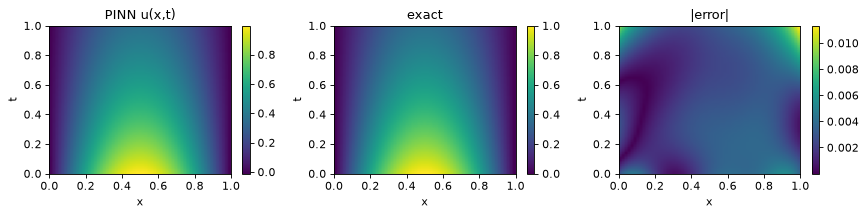

In [5]:
ALPHA = 0.1
seed_all()
heat_net = mlp(2, 1, width=32, depth=3)
opt = torch.optim.Adam(heat_net.parameters(), lr=3e-3)
u_heat = lambda x, t: heat_net(torch.cat([x, t], dim=1))

t0 = time.time()
for step in range(2000):
    # 1) PDE residual at random interior points
    x = torch.rand(400, 1, requires_grad=True); t = torch.rand(400, 1, requires_grad=True)
    u = u_heat(x, t)
    u_t = grad(u, t); u_x = grad(u, x); u_xx = grad(u_x, x)
    loss_pde = (u_t - ALPHA * u_xx).pow(2).mean()
    # 2) initial condition u(x, 0) = sin(pi x)
    xi = torch.rand(100, 1)
    loss_ic = (u_heat(xi, torch.zeros_like(xi)) - torch.sin(math.pi * xi)).pow(2).mean()
    # 3) boundary conditions u(0, t) = u(1, t) = 0
    tb = torch.rand(100, 1); xb = torch.randint(0, 2, (100, 1)).float()
    loss_bc = u_heat(xb, tb).pow(2).mean()
    loss = loss_pde + loss_ic + loss_bc
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 500 == 0 or step == 1999:
        print(f"step {step:4d}  pde {loss_pde.item():.2e}  ic {loss_ic.item():.2e}  bc {loss_bc.item():.2e}")
print(f"time {time.time() - t0:.1f} s")

X, TT = np.meshgrid(np.linspace(0, 1, 61), np.linspace(0, 1, 61))
with torch.no_grad():
    U = heat_net(torch.tensor(np.c_[X.ravel(), TT.ravel()], dtype=torch.float32)).numpy().reshape(X.shape)
U_exact = np.exp(-ALPHA * np.pi**2 * TT) * np.sin(np.pi * X)
print("relative L2 error vs exact solution:", round(float(np.linalg.norm(U - U_exact) / np.linalg.norm(U_exact)), 4))

fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
for a, Z, title in zip(ax, [U, U_exact, np.abs(U - U_exact)], ["PINN u(x,t)", "exact", "|error|"]):
    im = a.imshow(Z, origin="lower", extent=[0, 1, 0, 1], aspect="auto", cmap="viridis")
    a.set_xlabel("x"); a.set_ylabel("t"); a.set_title(title); fig.colorbar(im, ax=a)
plt.tight_layout(); plt.show()

**What to notice.** The network solved a PDE from the rules alone. That is the "mesh-free solver" view of PINNs: no grid, no time-stepping, and the answer is a smooth function you can evaluate (and differentiate) anywhere. For this simple, smooth problem a classical finite-difference solver would still be faster; PINNs pay off more in the inverse and data-assimilation settings below.

### 2.4 Demo (c): an inverse problem, learning the damping coefficient

Now pretend we **do not know** the friction $\mu$. We have 40 noisy measurements over $[0, 6]$ and we know the *form* of the equation $\ddot x + \mu\dot x + kx = 0$. We make $\mu$ a trainable parameter, next to the network weights. The data loss pulls the curve towards the measurements; the residual loss can only be small if $\mu$ takes the value that makes the curve obey the equation.

$$\min_{\theta,\ \mu}\ \frac{1}{N_d}\sum_i \big(x_\theta(t_i) - x_i^{\text{obs}}\big)^2 + \lambda_r \frac{1}{N_r}\sum_j \big(\ddot x_\theta + \mu\,\dot x_\theta + k\,x_\theta\big)^2(t_j)$$

time 8.2 s | true mu = 0.4 | learned mu = 0.393


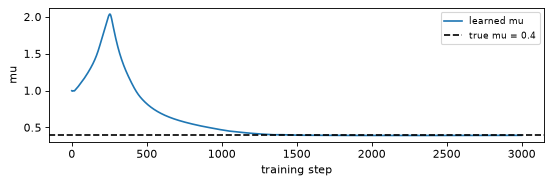

In [6]:
rng = np.random.default_rng(1)
t_inv = np.sort(rng.uniform(0, T_END, 40))
x_inv = oscillator_exact(t_inv) + 0.03 * rng.standard_normal(40)
td = torch.tensor(t_inv, dtype=torch.float32)[:, None]
xd = torch.tensor(x_inv, dtype=torch.float32)[:, None]

seed_all()
inv_net = mlp(1, 1, width=32, depth=3)
mu_hat = nn.Parameter(torch.tensor(1.0))                 # initial guess (true value is 0.4)
opt = torch.optim.Adam(list(inv_net.parameters()) + [mu_hat], lr=3e-3)
sched = torch.optim.lr_scheduler.StepLR(opt, step_size=1500, gamma=0.3)  # smaller steps later
u = lambda t: inv_net(t / T_END)
t_col = torch.linspace(0, T_END, 150)[:, None].requires_grad_(True)

history = []
t0 = time.time()
for step in range(3000):
    x = u(t_col); xt = grad(x, t_col); xtt = grad(xt, t_col)
    loss = (u(td) - xd).pow(2).mean() + 1e-2 * (xtt + mu_hat * xt + K * x).pow(2).mean()
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    history.append(mu_hat.item())
print(f"time {time.time() - t0:.1f} s | true mu = {MU_TRUE} | learned mu = {mu_hat.item():.3f}")

plt.figure(figsize=(7, 2.4))
plt.plot(history, label="learned mu"); plt.axhline(MU_TRUE, color="k", ls="--", label="true mu = 0.4")
plt.xlabel("training step"); plt.ylabel("mu"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

**What to notice.** The damping coefficient moves from the wrong guess (1.0) towards the true value, using only noisy position data. Nobody measured velocity or acceleration; autograd computed them from the network. This is the most popular real use of PINNs: estimating hidden physical parameters (material stiffness, diffusion constants, reaction rates, blood-flow properties) from measurements. The estimate is only as good as the noise level, the amount of data and the correctness of the assumed equation.

### 2.5 Practical tips and failure modes

| Topic | What goes wrong | What people do |
|---|---|---|
| **Loss weighting** ($\lambda$) | the residual, boundary and data terms have very different sizes, so one dominates and the others are ignored | scale inputs/outputs to about $[-1, 1]$; tune $\lambda$ by hand; adaptive schemes that balance gradient sizes (Wang, Teng and Perdikaris, 2021), or let each point have its own learnable weight (self-adaptive PINNs) |
| **Hard constraints** | soft boundary losses are never exactly satisfied | build the condition into the output, e.g. $u(x,t) = x(1-x)\,\text{NN}(x,t)$ makes $u(0)=u(1)=0$ exact |
| **Collocation sampling** | too few points, or points in the wrong places | random re-sampling each step (as in demo b), Latin hypercube or Sobol sequences, **residual-based adaptive refinement** (add points where the residual is largest) |
| **Spectral bias** | MLPs learn smooth, low-frequency shapes first and struggle with fast oscillations | **Fourier feature** inputs (code below), sine activations (Section 6), or splitting the domain |
| **Stiff and multiscale problems** | fast and slow processes together (chemistry, boundary layers, shocks in Burgers' equation with small viscosity) make the loss landscape very hard; the PINN converges to a wrong, smooth answer | non-dimensionalise the equation, curriculum training (start with an easy parameter, move to the hard one), domain decomposition (XPINN, FBPINN), or use a classical solver |
| **Long time horizons** | the network fits late times before early times are right, breaking causality | train in time windows, or weight later times by how well earlier times are already solved ("causal training") |
| **Optimizer** | Adam alone stalls at moderate accuracy | Adam first, then the quasi-Newton optimizer L-BFGS (`torch.optim.LBFGS`) for the final polish |
| **Cost** | every step needs higher-order autograd at many points | small networks, tanh or other smooth activations (ReLU has zero second derivative, so it is a poor choice for PDEs with $u_{xx}$) |

**Honest summary.** PINNs are elegant and great for inverse problems and data assimilation. For standard forward simulations they are usually slower and less accurate than mature numerical solvers, and they can fail silently on stiff, chaotic or multiscale problems, so always check the residual *and* compare with a reference solution when one exists.

In [7]:
# Fourier feature embedding: map a low-dimensional input to sines and cosines of many frequencies.
# gamma(v) = [cos(2 pi B v), sin(2 pi B v)],  with B a fixed random matrix (not trained).
class FourierFeatures(nn.Module):
    def __init__(self, n_in, n_features=16, sigma=5.0):
        super().__init__()
        self.register_buffer("B", sigma * torch.randn(n_in, n_features))   # fixed, not trained
    def forward(self, v):
        proj = 2 * math.pi * v @ self.B
        return torch.cat([torch.cos(proj), torch.sin(proj)], dim=-1)

ff = FourierFeatures(n_in=2, n_features=16)
print("input (x, t) shape:", (5, 2), "-> embedded shape:", tuple(ff(torch.rand(5, 2)).shape))
print("A PINN would use nn.Sequential(ff, mlp(32, 1)) instead of mlp(2, 1). Larger sigma = higher frequencies.")

input (x, t) shape: (5, 2) -> embedded shape: (5, 32)
A PINN would use nn.Sequential(ff, mlp(32, 1)) instead of mlp(2, 1). Larger sigma = higher frequencies.


### 2.6 Tools

You rarely write PINNs from scratch in practice. Common libraries (as of late 2026; check each project's docs for current APIs):

| Tool | What it is |
|---|---|
| **DeepXDE** (Lu et al.) | Python library for PINNs and DeepONets; supports PyTorch, TensorFlow, JAX and PaddlePaddle back ends; geometry, boundary conditions and adaptive sampling built in |
| **NVIDIA PhysicsNeMo** (formerly **Modulus**) | open-source framework for physics-ML at scale: PINNs, neural operators (FNO, AFNO), graph networks for meshes, GPU training |
| **NeuroDiffEq** | small PyTorch library focused on solving ODEs/PDEs with networks |
| **NeuralPDE.jl / SciML** (Julia) | PINNs and universal differential equations in the Julia SciML ecosystem |

A sketch of demo (b) in DeepXDE (not run here; DeepXDE is not installed in this environment):

```python
import deepxde as dde, numpy as np
geom = dde.geometry.GeometryXTime(dde.geometry.Interval(0, 1), dde.geometry.TimeDomain(0, 1))
def pde(x, u):                                    # x[:, 0] = space, x[:, 1] = time
    u_t = dde.grad.jacobian(u, x, i=0, j=1)
    u_xx = dde.grad.hessian(u, x, i=0, j=0)
    return u_t - 0.1 * u_xx
bc = dde.icbc.DirichletBC(geom, lambda x: 0, lambda x, on_boundary: on_boundary)
ic = dde.icbc.IC(geom, lambda x: np.sin(np.pi * x[:, 0:1]), lambda x, on_initial: on_initial)
data = dde.data.TimePDE(geom, pde, [bc, ic], num_domain=2000, num_boundary=100, num_initial=100)
model = dde.Model(data, dde.nn.FNN([2] + [32] * 3 + [1], "tanh", "Glorot normal"))
model.compile("adam", lr=1e-3); model.train(iterations=5000)
```

## 3. Neural operators: learning mappings between functions

### 3.1 Why learn an operator?

A PINN solves **one** problem: one initial condition, one set of parameters. Change the initial temperature profile and you must train again. Engineers often need thousands of solves (design search, uncertainty studies, real-time control). A **neural operator** learns the **solution operator** itself:

$$\mathcal{G}: \underbrace{u}_{\text{input function}} \;\longmapsto\; \underbrace{s = \mathcal{G}(u)}_{\text{output function}}$$

for example "initial temperature profile $\mapsto$ temperature profile one second later". An **operator** is simply a function whose inputs and outputs are themselves functions.

**Simple analogy.** A PINN is a person who worked out the answer to one maths problem. A neural operator is a calculator: it was expensive to build, but it now answers any problem of that type instantly.

**How it works in practice.** Run a classical solver many times to create pairs (input function, output function), stored on grids; train the operator on those pairs (supervised learning); then use it as a fast **surrogate**. Physics losses can be added too (physics-informed DeepONet / PINO).

### 3.2 DeepONet: branch and trunk networks

**What it is.** DeepONet (Lu, Jin, Pang, Zhang and Karniadakis, 2021) is built on a universal approximation theorem for operators (Chen and Chen, 1995). It has two sub-networks:

- the **branch net** reads the input function $u$ sampled at $m$ fixed **sensor** points, $\big(u(x_1), \dots, u(x_m)\big)$, and outputs $p$ numbers $b_1, \dots, b_p$;
- the **trunk net** reads a query location $y$ and outputs $p$ numbers $t_1(y), \dots, t_p(y)$.

The prediction is their dot product:

$$\mathcal{G}_\theta(u)(y) = \sum_{k=1}^{p} b_k\big(u(x_1),\dots,u(x_m)\big)\; t_k(y) + b_0 .$$

In words: the trunk net learns a set of $p$ **basis shapes** over the output domain; the branch net learns **how much of each shape** this particular input function needs. This is like a learned Fourier series, where the trunk learns the "sines and cosines" and the branch learns the coefficients.

```mermaid
flowchart LR
    U["u at m sensors"] --> BR[branch net] --> BK["b_1..b_p"]
    Y[query point y] --> TR[trunk net] --> TK["t_1(y)..t_p(y)"]
    BK --> DOT((dot product))
    TK --> DOT
    DOT --> S["G(u)(y)"]
```

**Demo: learn the antiderivative operator** $\mathcal{G}(u)(y) = \int_0^y u(x)\,dx$. Input functions are random smooth curves (random sums of sines and cosines). The network never sees the integration rule; it learns it from 1000 example pairs and must work on new curves.

In [8]:
M_SENS = 50                                     # number of sensor points for the branch net
x_sens = np.linspace(0, 1, M_SENS)
KS = np.arange(1, 5)                            # frequencies 1..4

def random_function_family(n, rng):
    # u(x) = c + sum_k a_k sin(2 pi k x) + b_k cos(2 pi k x); the exact integral is known in closed form
    a = rng.standard_normal((n, 4)) / KS
    b = rng.standard_normal((n, 4)) / KS
    c = 0.5 * rng.standard_normal((n, 1))
    def u(x):
        arg = 2 * np.pi * np.outer(KS, x)
        return c + a @ np.sin(arg) + b @ np.cos(arg)
    def s(x):   # integral from 0 to x
        arg = 2 * np.pi * np.outer(KS, x)
        k = 2 * np.pi * KS[:, None]
        return c * x[None, :] + a @ ((1 - np.cos(arg)) / k) + b @ (np.sin(arg) / k)
    return u, s

rng = np.random.default_rng(0)
N_TRAIN, P_QUERY = 1000, 20
u_fn, s_fn = random_function_family(N_TRAIN, rng)
U_train = u_fn(x_sens)                                     # (1000, 50) branch inputs
Y_train = rng.uniform(0, 1, (N_TRAIN, P_QUERY))            # random query points per function
S_train = np.stack([s_fn(Y_train[i])[i] for i in range(N_TRAIN)])   # (1000, 20) targets
print("branch input", U_train.shape, "| trunk input", Y_train.shape, "| targets", S_train.shape)

branch input (1000, 50) | trunk input (1000, 20) | targets (1000, 20)


DeepONet params 15873 | final train MSE 7.08e-04 | time 21.9 s
test relative L2 error on unseen functions: median 0.087
relative L2 error on out-of-family u = 3x^2: 0.297


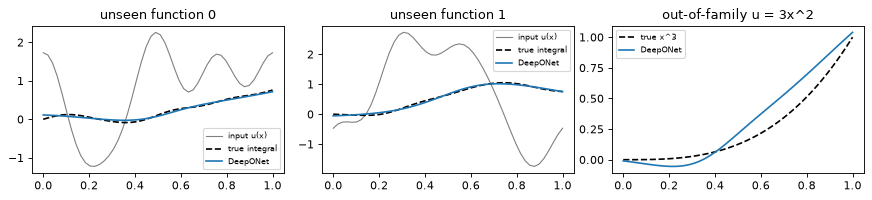

In [9]:
class DeepONet(nn.Module):
    def __init__(self, m, p=32, width=64):
        super().__init__()
        self.branch = mlp(m, p, width=width, depth=2)       # reads the whole input function
        self.trunk = mlp(1, p, width=width, depth=2)        # reads one query location
        self.trunk_act = nn.Tanh()
        self.b0 = nn.Parameter(torch.zeros(1))
    def forward(self, U, Y):        # U: (n, m), Y: (n, P)
        b = self.branch(U)                                   # (n, p)
        t = self.trunk_act(self.trunk(Y.unsqueeze(-1)))      # (n, P, p)
        return torch.einsum("np,nqp->nq", b, t) + self.b0    # (n, P)

seed_all()
don = DeepONet(M_SENS)
opt = torch.optim.Adam(don.parameters(), lr=1e-3)
Ut, Yt, St = (torch.tensor(a, dtype=torch.float32) for a in (U_train, Y_train, S_train))
t0 = time.time()
for step in range(1500):
    loss = (don(Ut, Yt) - St).pow(2).mean()
    opt.zero_grad(); loss.backward(); opt.step()
print(f"DeepONet params {n_params(don)} | final train MSE {loss.item():.2e} | time {time.time() - t0:.1f} s")

# test on 200 NEW random functions, on a fine grid of query points
u_te, s_te = random_function_family(200, np.random.default_rng(123))
y_grid = np.linspace(0, 1, 101)
U_te = torch.tensor(u_te(x_sens), dtype=torch.float32)
Y_te = torch.tensor(np.tile(y_grid, (200, 1)), dtype=torch.float32)
with torch.no_grad():
    S_pred = don(U_te, Y_te).numpy()
S_true = s_te(y_grid)
rel = np.linalg.norm(S_pred - S_true, axis=1) / np.linalg.norm(S_true, axis=1)
print(f"test relative L2 error on unseen functions: median {np.median(rel):.3f}")

# out-of-family input: u(x) = 3 x^2 (not a sum of sines), true integral x^3
U_ood = torch.tensor(3 * x_sens[None, :] ** 2, dtype=torch.float32)
with torch.no_grad():
    s_ood = don(U_ood, torch.tensor(y_grid[None, :], dtype=torch.float32)).numpy().ravel()
print(f"relative L2 error on out-of-family u = 3x^2: {np.linalg.norm(s_ood - y_grid**3) / np.linalg.norm(y_grid**3):.3f}")

fig, ax = plt.subplots(1, 3, figsize=(11, 2.6))
for j, a in enumerate(ax[:2]):
    a.plot(x_sens, u_te(x_sens)[j], c="grey", lw=1, label="input u(x)")
    a.plot(y_grid, S_true[j], "k--", label="true integral")
    a.plot(y_grid, S_pred[j], c="tab:blue", label="DeepONet")
    a.set_title(f"unseen function {j}"); a.legend(fontsize=7)
ax[2].plot(y_grid, y_grid**3, "k--", label="true x^3"); ax[2].plot(y_grid, s_ood, c="tab:blue", label="DeepONet")
ax[2].set_title("out-of-family u = 3x^2"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

**What to notice.** On new functions *from the same family* DeepONet is accurate: it learned "integrate" as an operation, not a lookup table. On a function from a *different* family the error is larger. That is the main practical limit of all neural operators: they are excellent interpolators within the distribution of training inputs, and much less reliable outside it.

### 3.3 The Fourier neural operator (FNO)

**What it is.** The FNO (Li, Kovachki, Azizzadenesheli, Liu, Bhattacharya, Stuart and Anandkumar, 2021) is built from **Fourier layers**. Each layer:
1. takes the current hidden function $v(x)$ (several channels on a grid),
2. converts it to frequencies with the **fast Fourier transform (FFT)**,
3. keeps only the lowest $k_{\max}$ frequencies and multiplies each by a learned complex matrix $R$ (this mixes channels, frequency by frequency),
4. converts back with the inverse FFT, adds a simple pointwise linear path $W v$, and applies a nonlinearity.

$$v_{l+1}(x) = \sigma\Big( W\,v_l(x) + \mathcal{F}^{-1}\big[\,R_\phi \cdot (\mathcal{F} v_l)\,\big](x) \Big)$$

In words: *a convolution done in frequency space*. A normal CNN has a small kernel that sees a few neighbours; a spectral convolution has a kernel that spans the **whole domain**, but only at low frequencies. Many physical solution operators (diffusion, waves, flow) are naturally simple in frequency space, which is why this works so well.

**Simple analogy.** A sound engineer with an equaliser. Instead of editing the waveform sample by sample, they turn the bass, middle and treble knobs. The FNO learns how to set the knobs.

**Resolution invariance.** The learned weights $R$ belong to *frequencies*, not to grid points. Frequency number 3 means the same wave whether you sample it at 64 or 256 points. So an FNO trained at one grid resolution can be evaluated at another ("zero-shot super-resolution"), which a normal CNN cannot do in the same way.

In [10]:
class SpectralConv1d(nn.Module):
    # The core FNO layer: FFT -> keep `modes` lowest frequencies -> multiply by learned complex weights -> inverse FFT
    def __init__(self, c_in, c_out, modes):
        super().__init__()
        self.modes = modes
        scale = 1.0 / (c_in * c_out)
        self.weight = nn.Parameter(scale * torch.randn(c_in, c_out, modes, dtype=torch.cfloat))
    def forward(self, v):                         # v: (batch, channels, n_grid), real
        v_hat = torch.fft.rfft(v)                 # (batch, c_in, n_grid//2 + 1), complex
        out_hat = torch.zeros(v.shape[0], self.weight.shape[1], v_hat.shape[-1], dtype=torch.cfloat)
        # mix channels separately for each kept frequency k:  out[b,o,k] = sum_i v_hat[b,i,k] * W[i,o,k]
        out_hat[:, :, :self.modes] = torch.einsum("bik,iok->bok", v_hat[:, :, :self.modes], self.weight)
        return torch.fft.irfft(out_hat, n=v.shape[-1])   # back to the grid, same length as input

class FNO1d(nn.Module):
    def __init__(self, modes=12, width=24, n_layers=3):
        super().__init__()
        self.lift = nn.Conv1d(2, width, 1)        # inputs per grid point: u0(x) and the coordinate x
        self.spectral = nn.ModuleList([SpectralConv1d(width, width, modes) for _ in range(n_layers)])
        self.pointwise = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(n_layers)])
        self.project = nn.Sequential(nn.Conv1d(width, 64, 1), nn.GELU(), nn.Conv1d(64, 1, 1))
    def forward(self, u0):                        # u0: (batch, n_grid)
        n = u0.shape[-1]
        xgrid = torch.linspace(0, 1, n + 1)[:-1].expand(u0.shape[0], n)   # periodic grid on [0, 1)
        v = self.lift(torch.stack([u0, xgrid], dim=1))
        for i, (sc, pw) in enumerate(zip(self.spectral, self.pointwise)):
            v = sc(v) + pw(v)
            if i < len(self.spectral) - 1:
                v = F.gelu(v)
        return self.project(v).squeeze(1)

layer = SpectralConv1d(4, 4, modes=6)
for n in (32, 64, 128):    # the SAME layer runs on any grid size
    print(f"grid {n:4d}: input {(2, 4, n)} -> output {tuple(layer(torch.randn(2, 4, n)).shape)}")

grid   32: input (2, 4, 32) -> output (2, 4, 32)
grid   64: input (2, 4, 64) -> output (2, 4, 64)
grid  128: input (2, 4, 128) -> output (2, 4, 128)


**Demo: learn the diffusion solution operator.** On a periodic rod, $u_t = \nu u_{xx}$ with $\nu = 0.01$. The operator maps a random initial profile $u_0(x)$ to the profile at time $T = 0.5$. Our "simulator" is exact: in Fourier space each frequency $k$ just decays by $e^{-\nu (2\pi k)^2 T}$, so high-frequency wiggles die fast. We train at 64 grid points and then test at 64, 128 and 256 points.

(Honest note: diffusion is a *linear* operator that is diagonal in Fourier space, so it is an easy target for an FNO. The same code is used for nonlinear problems such as Burgers' or Navier-Stokes equations; only the training data, generated by a real solver, changes.)

FNO params 24273 | final batch MSE 1.41e-05 | time 7.1 s
 test grid size  median relative L2 error
             64                    0.0045
            128                    0.0047
            256                    0.0047


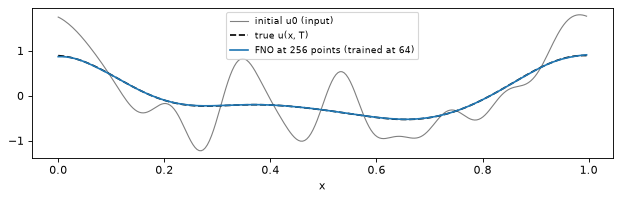

In [11]:
NU, T_FINAL, KMAX = 0.01, 0.5, 10

def diffusion_pairs(n_samples, n_grid, rng):
    # random initial conditions as Fourier series; exact solution at T_FINAL by damping each mode
    k = np.arange(1, KMAX + 1)
    a = rng.standard_normal((n_samples, KMAX)) / k
    b = rng.standard_normal((n_samples, KMAX)) / k
    x = np.arange(n_grid) / n_grid
    S, C = np.sin(2 * np.pi * np.outer(k, x)), np.cos(2 * np.pi * np.outer(k, x))
    decay = np.exp(-NU * (2 * np.pi * k) ** 2 * T_FINAL)
    u0 = a @ S + b @ C
    uT = (a * decay) @ S + (b * decay) @ C
    return torch.tensor(u0, dtype=torch.float32), torch.tensor(uT, dtype=torch.float32)

rng = np.random.default_rng(0)
u0_tr, uT_tr = diffusion_pairs(800, 64, rng)
seed_all()
fno = FNO1d(modes=12, width=24, n_layers=3)
opt = torch.optim.Adam(fno.parameters(), lr=3e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=600)
t0 = time.time()
for step in range(600):
    idx = torch.randint(0, 800, (50,))
    loss = (fno(u0_tr[idx]) - uT_tr[idx]).pow(2).mean()
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
print(f"FNO params {n_params(fno)} | final batch MSE {loss.item():.2e} | time {time.time() - t0:.1f} s")

rows = []
for n_grid in (64, 128, 256):          # trained ONLY at 64
    u0_te, uT_te = diffusion_pairs(200, n_grid, np.random.default_rng(7))
    with torch.no_grad():
        pred = fno(u0_te)
    rel = (torch.linalg.norm(pred - uT_te, dim=1) / torch.linalg.norm(uT_te, dim=1)).median().item()
    rows.append({"test grid size": n_grid, "median relative L2 error": round(rel, 4)})
print(pd.DataFrame(rows).to_string(index=False))

u0_te, uT_te = diffusion_pairs(1, 256, np.random.default_rng(99))
with torch.no_grad():
    pred = fno(u0_te)
xg = np.arange(256) / 256
plt.figure(figsize=(8, 2.6))
plt.plot(xg, u0_te[0], c="grey", lw=1, label="initial u0 (input)")
plt.plot(xg, uT_te[0], "k--", label="true u(x, T)")
plt.plot(xg, pred[0], c="tab:blue", label="FNO at 256 points (trained at 64)")
plt.legend(fontsize=8); plt.xlabel("x"); plt.tight_layout(); plt.show()

### 3.4 Where neural operators are used today, and their limits

| Area | Examples (as of late 2026, described generally) |
|---|---|
| **Weather and climate** | data-driven global forecast models now run alongside physics models at major centres. FourCastNet uses an adaptive Fourier neural operator; GraphCast uses a graph neural network on a mesh of the globe; Pangu-Weather uses a 3D transformer; GenCast uses diffusion for probabilistic ensembles. They forecast in seconds to minutes, compared with hours of supercomputer time |
| **CFD surrogates** | fast approximations of airflow and fluid flow for design search (cars, aircraft, turbines), often FNOs or graph networks on simulation meshes |
| **Subsurface and energy** | CO2 storage, groundwater and reservoir flow, where thousands of scenarios are needed |
| **Materials, fusion, medicine** | crack and stress fields, plasma behaviour, blood flow |

**Which one to pick**

| | Classical solver | PINN | DeepONet | FNO |
|---|---|---|---|---|
| Learns | nothing (computes) | one solution | an operator | an operator |
| Needs training data | no | little or none | many solved examples | many solved examples |
| Speed per new problem | slow to medium | retrain (slow) | instant | instant |
| Input format | any | coordinates | input function at fixed sensors | functions on a (usually regular) grid |
| Geometry | any (meshes) | any (mesh-free) | flexible (trunk takes any point) | regular grids best; extensions (Geo-FNO, graph operators) for meshes |

**Limits.** Neural operators need a lot of expensive simulation data up front, can be wrong outside the training distribution, often lose accuracy over long autoregressive rollouts (errors pile up step by step), and carry no built-in guarantee of conservation laws unless you add one.

## 4. Physics-structured dynamics

### 4.1 Neural ODEs (recap)

A **neural ODE** (Chen, Rubanova, Bettencourt and Duvenaud, 2018) lets a network define the *rule of change* of a hidden state, and an ODE solver produces the trajectory:

$$\frac{d\mathbf{h}}{dt} = f_\theta(\mathbf{h}, t), \qquad \mathbf{h}(T) = \mathbf{h}(0) + \int_0^T f_\theta(\mathbf{h}, t)\,dt .$$

A ResNet block $\mathbf{h}_{l+1} = \mathbf{h}_l + f(\mathbf{h}_l)$ is one Euler step of this equation, which is the bridge between deep learning and ODEs. Gradients can be computed memory-efficiently with the **adjoint method**. All of this (solvers, adjoint, FFJORD, latent ODEs) is taught in [`10_neural_ode.ipynb`](10_neural_ode.ipynb), so here we focus on a question it raises: *a generic $f_\theta$ can learn any dynamics, including ones that break physics. Can we make it respect conservation laws?*

### 4.2 Hamiltonian neural networks (HNN)

**What it is.** In classical mechanics, a system with position $q$ and momentum $p$ has a total energy, the **Hamiltonian** $H(q, p)$. Its motion follows Hamilton's equations:

$$\frac{dq}{dt} = \frac{\partial H}{\partial p}, \qquad \frac{dp}{dt} = -\frac{\partial H}{\partial q}.$$

A consequence is that energy is conserved: $\frac{dH}{dt} = \frac{\partial H}{\partial q}\dot q + \frac{\partial H}{\partial p}\dot p = \frac{\partial H}{\partial q}\frac{\partial H}{\partial p} - \frac{\partial H}{\partial p}\frac{\partial H}{\partial q} = 0$.

An HNN (Greydanus, Dzamba and Yosinski, 2019) **learns the single scalar $H_\theta(q,p)$** with a network, and gets the velocity field by differentiating it (autograd again). A plain network instead learns $(\dot q, \dot p)$ directly.

**Simple analogy.** A plain network is told "copy these arrows". An HNN is told "draw a landscape of heights; the arrows must run along the contour lines". Any arrow field that runs along contour lines cannot climb or descend, so energy cannot drift.

**Demo: a mass on a spring**, $H = \tfrac12(q^2 + p^2)$. Both networks learn from 200 noisy samples of the true velocity field. Then we integrate each learned field for a long time and watch the energy.

In [12]:
rng = np.random.default_rng(0)
Z = rng.uniform(-1.5, 1.5, (200, 2))                        # states (q, p)
dZ = np.c_[Z[:, 1], -Z[:, 0]] + 0.05 * rng.standard_normal((200, 2))   # true (dq/dt, dp/dt) = (p, -q) + noise
Zt, dZt = torch.tensor(Z, dtype=torch.float32), torch.tensor(dZ, dtype=torch.float32)

seed_all()
baseline = mlp(2, 2, width=64, depth=2)                      # predicts (dq/dt, dp/dt) directly
H_net = mlp(2, 1, width=64, depth=2)                         # predicts one number: the energy H

def hnn_field(z):
    # vector field from the learned Hamiltonian: (dH/dp, -dH/dq)
    with torch.enable_grad():
        z = z.detach().requires_grad_(True) if not z.requires_grad else z
        dH = grad(H_net(z), z)
    return torch.stack([dH[:, 1], -dH[:, 0]], dim=1)

t0 = time.time()
for model, field in [(baseline, lambda z: baseline(z)), (H_net, hnn_field)]:
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    for step in range(1500):
        loss = (field(Zt.clone().requires_grad_(True)) - dZt).pow(2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    print(f"{'baseline' if model is baseline else 'HNN':8s} final MSE on the arrows: {loss.item():.4f}")
print(f"time {time.time() - t0:.1f} s")

baseline final MSE on the arrows: 0.0024


HNN      final MSE on the arrows: 0.0024
time 3.5 s


                      true  baseline NN    HNN
energy after 1 step  0.500        0.500  0.501
energy at t=60       0.500        0.374  0.500
drift %             -0.001      -25.205 -0.053


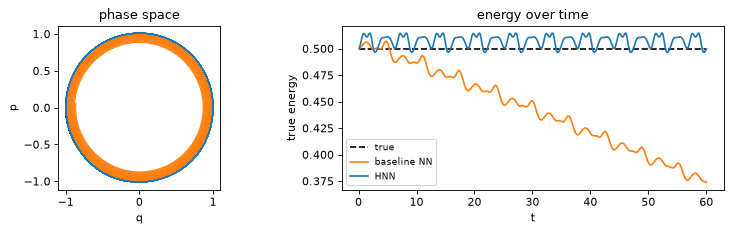

In [13]:
def rk4_rollout(field, z0, dt=0.1, n_steps=600):
    # integrate dz/dt = field(z) with the classical 4th-order Runge-Kutta method
    z, traj = torch.tensor([z0], dtype=torch.float32), []
    for _ in range(n_steps):
        k1 = field(z); k2 = field(z + dt / 2 * k1); k3 = field(z + dt / 2 * k2); k4 = field(z + dt * k3)
        z = (z + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)).detach()
        traj.append(z.numpy()[0])
    return np.array(traj)

true_field = lambda z: torch.stack([z[:, 1], -z[:, 0]], dim=1)
z0 = [1.0, 0.0]
trajs = {"true": rk4_rollout(true_field, z0),
         "baseline NN": rk4_rollout(lambda z: baseline(z).detach(), z0),
         "HNN": rk4_rollout(lambda z: hnn_field(z).detach(), z0)}
energy = {k: 0.5 * (v ** 2).sum(1) for k, v in trajs.items()}    # TRUE energy of each trajectory
print(pd.DataFrame({k: [e[0], e[-1], 100 * (e[-1] - 0.5) / 0.5] for k, e in energy.items()},
                   index=["energy after 1 step", "energy at t=60", "drift %"]).round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for (k, v), c in zip(trajs.items(), ["k", "tab:orange", "tab:blue"]):
    ax[0].plot(v[:, 0], v[:, 1], c=c, lw=1, ls="--" if k == "true" else "-", label=k)
    ax[1].plot(np.arange(1, 601) * 0.1, energy[k], c=c, ls="--" if k == "true" else "-", label=k)
ax[0].set_xlabel("q"); ax[0].set_ylabel("p"); ax[0].set_title("phase space"); ax[0].set_aspect("equal")
ax[1].set_xlabel("t"); ax[1].set_ylabel("true energy"); ax[1].set_title("energy over time"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to notice.** Both networks fit the arrows about equally well, yet over a long rollout the plain network's small errors accumulate into a steady energy drift (its orbit spirals in or out). The HNN's orbit stays on a closed loop, because by construction it conserves *its own* learned energy; the remaining error comes from how well $H_\theta$ matches the true $H$, not from drift.

**Used today:** learned simulators for mechanical and molecular systems, robotics, and as a teaching example of "structure-preserving" machine learning. **Limits:** needs the right coordinates ($q$, $p$ are not always measured; momentum is often unknown), plain HNNs cannot model friction or energy input (extensions add a dissipation term, e.g. port-Hamiltonian networks), and chaotic systems are still hard to predict for long.

### 4.3 Lagrangian neural networks (LNN)

Lagrangian mechanics uses positions and velocities $(q, \dot q)$, which are easier to measure than momenta. An LNN (Cranmer, Greydanus, Hoyer, Battaglia, Spergel and Ho, 2020) learns a scalar **Lagrangian** $L_\theta(q, \dot q)$ and gets the acceleration from the Euler-Lagrange equation:

$$\frac{d}{dt}\frac{\partial L}{\partial \dot q} = \frac{\partial L}{\partial q} \quad\Longrightarrow\quad \ddot q = \Big(\nabla_{\dot q}\nabla_{\dot q}^{\top} L\Big)^{-1}\Big[\nabla_q L - \big(\nabla_{q}\nabla_{\dot q}^{\top} L\big)\,\dot q\Big].$$

In words: the same "learn one energy-like scalar, derive the motion" trick, but it needs second derivatives and a matrix inverse (a Hessian), so it is costlier. See also the short sections in [`10_neural_ode.ipynb`](10_neural_ode.ipynb).

### 4.4 Universal differential equations (UDE)

**What it is.** Often we know *most* of the equation but not one term (an unknown friction law, an unknown interaction in an ecosystem, an unknown reaction rate). A universal differential equation (Rackauckas et al., 2020) keeps the known part and lets a network fill in the gap:

$$\frac{d\mathbf{u}}{dt} = \underbrace{f_{\text{known}}(\mathbf{u}, t)}_{\text{physics we trust}} + \underbrace{\text{NN}_\theta(\mathbf{u}, t)}_{\text{what we don't know}} .$$

Train it like a neural ODE (simulate, compare with data, backpropagate). Afterwards, a sparse regression method such as **SINDy** (sparse identification of nonlinear dynamics) can turn the learned NN term into a short readable formula. Sketch (not run):

```python
def rhs(u, t):                       # predator-prey with an unknown interaction term
    x, y = u[..., 0], u[..., 1]
    known = torch.stack([1.3 * x, -1.8 * y], -1)      # growth and death rates we trust
    return known + nn_theta(u)                         # the network learns the interaction
```

**Used today:** systems biology, pharmacology, climate model corrections, battery and engine modelling. **Limits:** the learned term can absorb modelling errors from anywhere, so it is only identifiable if the data really constrain it.

## 5. Kolmogorov-Arnold networks (KAN)

**What it is.** In an MLP, each **edge** carries one number (a weight) and each **node** applies a fixed activation like ReLU. In a KAN (Liu et al., 2024), each **edge carries a learnable one-variable function** $\phi(x)$, and nodes just **add**. The idea comes from the **Kolmogorov-Arnold representation theorem**: any continuous function of several variables on a bounded domain can be written using only sums and one-variable functions:

$$f(x_1, \dots, x_n) = \sum_{q=0}^{2n} \Phi_q\!\left(\sum_{p=1}^{n} \phi_{q,p}(x_p)\right).$$

A KAN layer generalises this: $\displaystyle x_{l+1, j} = \sum_{i} \phi_{l, j, i}(x_{l, i})$. Each $\phi$ is a small curve made of **B-splines** (smooth, local "bump" functions on a grid) plus a simple base function:

$$\phi(x) = w_b\,\mathrm{silu}(x) + \sum_{c} c_c\, B_c(x).$$

The coefficients $c_c$ are learned.

**Simple analogy.** An MLP is a mixing desk with fixed knobs (weights) and the same distortion pedal on every channel. A KAN replaces each knob with a custom-shaped dial curve you can see and read.

| | MLP | KAN |
|---|---|---|
| Learnable thing on each edge | a number (weight) | a 1-D function (spline coefficients) |
| Node operation | fixed activation (ReLU, GELU) | plain sum |
| Interpretability | hard | each edge is a curve you can plot and match to a formula |
| Speed | very fast, GPU friendly matrix multiply | slower per parameter (spline evaluation) |
| Maturity | decades of tooling | new (2024), active research |

First, what B-spline basis functions look like:

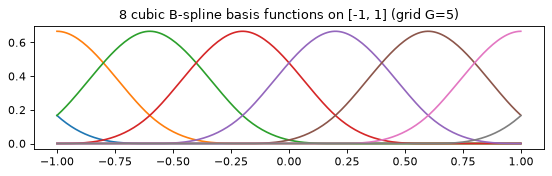

In [14]:
def bspline_basis(x, grid, k=3):
    # Cox-de Boor recursion. x: (N, n_in); grid: (n_in, G + 2k + 1) knots.
    # Returns (N, n_in, G + k): the value of every basis "bump" at every input.
    x = x.unsqueeze(-1)
    B = ((x >= grid[:, :-1]) & (x < grid[:, 1:])).float()          # order 0: boxes
    for p in range(1, k + 1):                                       # raise the order step by step
        left = (x - grid[:, :-(p + 1)]) / (grid[:, p:-1] - grid[:, :-(p + 1)])
        right = (grid[:, p + 1:] - x) / (grid[:, p + 1:] - grid[:, 1:-p])
        B = left * B[..., :-1] + right * B[..., 1:]
    return B

def make_grid(n_in, G, k, lo, hi):
    h = (hi - lo) / G
    return (torch.arange(-k, G + k + 1).float() * h + lo).repeat(n_in, 1)   # extended knot vector

xs_plot = torch.linspace(-1, 0.999, 200)[:, None]
B = bspline_basis(xs_plot, make_grid(1, G=5, k=3, lo=-1, hi=1))[:, 0, :]
plt.figure(figsize=(7, 2.3)); plt.plot(xs_plot, B.numpy())
plt.title(f"{B.shape[1]} cubic B-spline basis functions on [-1, 1] (grid G=5)"); plt.tight_layout(); plt.show()

In [15]:
class KANLayer(nn.Module):
    # every (input i, output j) pair has its own curve phi_ij(x) = w_b * silu(x) + sum_c coef_ijc * B_c(x)
    def __init__(self, n_in, n_out, G=8, k=3, lo=-1.0, hi=1.0):
        super().__init__()
        self.k = k
        self.register_buffer("grid", make_grid(n_in, G, k, lo, hi))
        self.coef = nn.Parameter(0.1 * torch.randn(n_in, n_out, G + k))
        self.w_base = nn.Parameter(torch.full((n_in, n_out), 0.5 / math.sqrt(n_in)))
    def edge_values(self, x):                       # (N, n_in) -> (N, n_in, n_out): each edge's output
        B = bspline_basis(x, self.grid, self.k)
        return torch.einsum("nic,ioc->nio", B, self.coef) + F.silu(x).unsqueeze(-1) * self.w_base
    def forward(self, x):
        return self.edge_values(x).sum(dim=1)       # nodes just add their incoming edges

# target: the classic KAN example f(x, y) = exp(sin(pi x) + y^2) on [-1, 1]^2
f_true = lambda X: np.exp(np.sin(np.pi * X[:, 0]) + X[:, 1] ** 2)
rng = np.random.default_rng(0)
X_tr = rng.uniform(-1, 1, (1000, 2)); X_te = rng.uniform(-1, 1, (1000, 2))
Xtr, Ytr = torch.tensor(X_tr, dtype=torch.float32), torch.tensor(f_true(X_tr), dtype=torch.float32)[:, None]
Xte, Yte = torch.tensor(X_te, dtype=torch.float32), torch.tensor(f_true(X_te), dtype=torch.float32)[:, None]

def fit(model, steps=1500, lr=1e-2):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(steps):
        loss = (model(Xtr) - Ytr).pow(2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return (model(Xte) - Yte).pow(2).mean().item()

seed_all()
kan1, kan2 = KANLayer(2, 1, G=8, lo=-1, hi=1), KANLayer(1, 1, G=8, lo=-2, hi=3)   # a [2, 1, 1] KAN
kan = nn.Sequential(kan1, kan2)
t0 = time.time(); kan_mse = fit(kan); t_kan = time.time() - t0
seed_all()
small_mlp = mlp(2, 1, width=16, depth=2, act=nn.SiLU)
t0 = time.time(); mlp_mse = fit(small_mlp, lr=3e-3); t_mlp = time.time() - t0
print(pd.DataFrame({"params": [n_params(kan), n_params(small_mlp)], "test MSE": [kan_mse, mlp_mse],
                    "train time (s)": [t_kan, t_mlp]}, index=["KAN [2,1,1]", "MLP 2-16-16-1"]).round(5))

               params  test MSE  train time (s)
KAN [2,1,1]        36   0.00002         4.56907
MLP 2-16-16-1     337   0.00972         1.37361


**"Reading off" the formula.** Because the KAN has shape $[2, 1, 1]$, its structure is $f(x,y) \approx \Phi\big(\phi_1(x) + \phi_2(y)\big)$. We plot each learned edge curve and compare it with a small library of candidate functions ($x$, $x^2$, $x^3$, $\sin \pi x$, $\cos \pi x$, $e^x$), fitting $a\,g(b\,z) + d$ for each candidate and picking the best $R^2$ (fraction of variance explained, 1.0 is perfect). The real `pykan` library does this with `auto_symbolic`, plus pruning to find the small structure first.

phi_1(x)  best match: +1.113 * sin(pi z) +0.397   R^2 = 1.0000
phi_2(y)  best match: +1.114 * z^2 +0.197   R^2 = 1.0000
Phi(h)    best match: +0.582 * exp(0.90 z) +0.008   R^2 = 1.0000


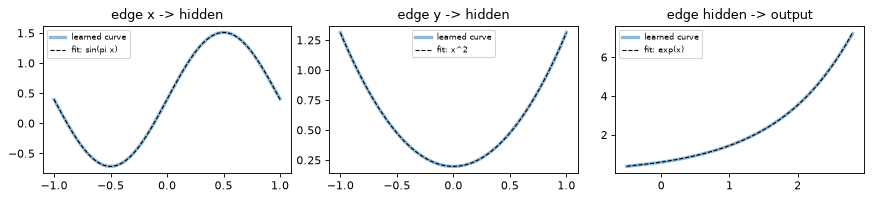

In [16]:
CANDIDATES = {"x": lambda z: z, "x^2": lambda z: z**2, "x^3": lambda z: z**3,
              "sin(pi x)": lambda z: np.sin(np.pi * z), "cos(pi x)": lambda z: np.cos(np.pi * z), "exp(x)": np.exp}

def best_symbolic(z, v, scales=(1.0,)):
    # fit v ~ a * g(b * z) + d for every candidate g and scale b; return the best one
    best = None
    for name, g in CANDIDATES.items():
        for b in scales:
            A = np.c_[g(b * z), np.ones_like(z)]
            (a, d), *_ = np.linalg.lstsq(A, v, rcond=None)
            r2 = 1 - np.sum((A @ [a, d] - v) ** 2) / np.sum((v - v.mean()) ** 2)
            if best is None or r2 > best[1]:
                best = (name, r2, a, b, d)
    return best

with torch.no_grad():
    z_in = np.linspace(-1, 1, 101)
    edges = kan1.edge_values(torch.tensor(np.c_[z_in, z_in], dtype=torch.float32))[:, :, 0].numpy()
    h_all = kan1(Xtr).numpy().ravel()
    z_hid = np.linspace(h_all.min(), h_all.max(), 101)
    outer = kan2.edge_values(torch.tensor(z_hid[:, None], dtype=torch.float32))[:, 0, 0].numpy()

fits = [best_symbolic(z_in, edges[:, 0]), best_symbolic(z_in, edges[:, 1]),
        best_symbolic(z_hid, outer, scales=np.linspace(0.2, 3, 57))]
import re
for label, (name, r2, a, b, d) in zip(["phi_1(x)", "phi_2(y)", "Phi(h)"], fits):
    arg = "z" if b == 1 else f"{b:.2f} z"
    shown = re.sub(r"\bx\b", arg, name)          # replace the variable x (not the x inside 'exp')
    print(f"{label:9s} best match: {a:+.3f} * {shown} {d:+.3f}   R^2 = {r2:.4f}")

fig, ax = plt.subplots(1, 3, figsize=(11, 2.6))
for a_, z, v, (name, r2, a, b, d), t in zip(ax, [z_in, z_in, z_hid], [edges[:, 0], edges[:, 1], outer], fits,
                                            ["edge x -> hidden", "edge y -> hidden", "edge hidden -> output"]):
    a_.plot(z, v, lw=3, alpha=0.5, label="learned curve")
    a_.plot(z, a * CANDIDATES[name](b * z) + d, "k--", lw=1, label=f"fit: {name}")
    a_.set_title(t); a_.legend(fontsize=7)
plt.tight_layout(); plt.show()

**What to notice.** The three learned curves match $\sin(\pi x)$, $y^2$ and an exponential almost perfectly, so we recover $f(x,y) \approx \exp\big(\sin(\pi x) + y^2\big)$ up to constants. The tiny KAN has about a tenth of the MLP's parameters. This is the appealing side of KANs: for **small problems that truly have a compact formula**, they can act as a symbolic-regression tool.

**Honest limits.**
- We chose the right shape $[2,1,1]$ by hand. On real data you start wider, then prune, and the result depends on many settings (grid size, regularisation, pruning thresholds).
- Spline evaluation is slower than a matrix multiply, and KANs are harder to scale to large inputs (images, text).
- Follow-up studies that compare at equal parameters or compute (for example "KAN or MLP: A Fairer Comparison", Yu et al., 2024) found MLPs match or beat KANs on many ordinary machine-learning tasks; the KAN advantage shows up mainly on symbolic, science-style functions.
- "Interpretable" only holds if the learned curves really are simple; on messy data they are just wiggly curves.

**Used today (late 2026):** mostly research: symbolic regression, small PDE solvers, and physics discovery. The `pykan` library implements KAN and its follow-up KAN 2.0. More background in [`10_neural_ode.ipynb`](10_neural_ode.ipynb) (Section 12).

## 6. Implicit neural representations (INR)

**What it is.** An implicit neural representation stores a signal *as a function*: a network that maps a **coordinate** to the **value** there. For an image, $f_\theta(x, y) = $ colour; for audio, $f_\theta(t) = $ amplitude; for a 3D shape, $f_\theta(x,y,z) = $ signed distance to the surface. The network's weights *are* the image. You can query it at any resolution, and you can take derivatives (edges, normals).

**Simple analogy.** A bitmap stores every pixel like a phone book. An INR stores a *rule* that can tell you the colour at any address, including addresses between the pixels.

**The problem: spectral bias.** A plain ReLU MLP learns smooth, low-frequency patterns first and struggles with sharp edges and fine texture. Two fixes:

1. **Fourier features** (Tancik et al., 2020): first map the coordinate to sines and cosines of random frequencies, $\gamma(\mathbf v) = [\cos(2\pi B\mathbf v), \sin(2\pi B\mathbf v)]$ with $B \sim \mathcal N(0, \sigma^2)$, then use a normal MLP. NeRF's "positional encoding" is the same idea with fixed frequencies.
2. **SIREN** (Sitzmann, Martel, Bergman, Lindell and Wetzstein, 2020): use **sine activations** in every layer, $\phi(\mathbf x) = \sin\big(\omega_0 (W\mathbf x + \mathbf b)\big)$ with $\omega_0 = 30$. The special **initialisation** matters: the first layer's weights are uniform in $[-1/n, 1/n]$, later layers' in $[-\sqrt{6/n}/\omega_0, \sqrt{6/n}/\omega_0]$ (with $n$ the number of inputs to the layer). This keeps the activations well spread through the depth so that training is stable. A bonus: the derivative of a sine is a cosine, so every derivative of a SIREN is again a SIREN-like network, which is why SIRENs are popular for PINN-style problems involving derivatives.

**Demo:** fit a 64 x 64 synthetic image (sharp edges plus a striped texture) with three networks of the same width and the same number of steps.

                  model  params  PSNR (dB)
               ReLU MLP   33537       17.8
Fourier features + ReLU   33153       56.0
                  SIREN   33537       35.2 
time 13.4 s


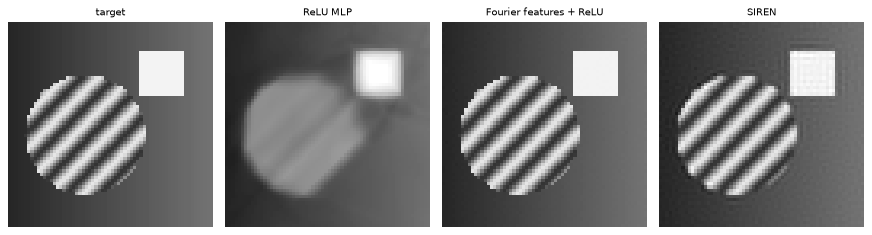

In [17]:
n = 64
yy, xx = np.meshgrid(np.linspace(-1, 1, n), np.linspace(-1, 1, n), indexing="ij")
img = 0.3 + 0.15 * xx                                                   # smooth background
disk = (xx + 0.25) ** 2 + (yy - 0.1) ** 2 < 0.35
img = np.where(disk, 0.55 + 0.35 * np.sin(12 * np.pi * (xx + yy) / 2), img)   # striped disk
img = np.where((np.abs(xx - 0.5) < 0.22) & (np.abs(yy + 0.5) < 0.22), 0.95, img)  # bright square
coords = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)          # (4096, 2)
target = torch.tensor(img.ravel(), dtype=torch.float32)[:, None]

class SineLayer(nn.Module):
    def __init__(self, n_in, n_out, w0=30.0, first=False):
        super().__init__()
        self.w0, self.lin = w0, nn.Linear(n_in, n_out)
        bound = 1 / n_in if first else math.sqrt(6 / n_in) / w0       # SIREN initialisation
        with torch.no_grad():
            self.lin.weight.uniform_(-bound, bound)
    def forward(self, x):
        return torch.sin(self.w0 * self.lin(x))

W = 128
def make_inr(kind):
    if kind == "ReLU MLP":
        return mlp(2, 1, width=W, depth=3, act=nn.ReLU)
    if kind == "Fourier features + ReLU":
        return nn.Sequential(FourierFeatures(2, n_features=W // 2, sigma=6.0), mlp(W, 1, width=W, depth=2, act=nn.ReLU))
    return nn.Sequential(SineLayer(2, W, first=True), SineLayer(W, W), SineLayer(W, W), nn.Linear(W, 1))

psnr = lambda mse: 10 * np.log10(1.0 / mse)    # peak signal-to-noise ratio, higher = better (dB)
recons, rows = {}, []
t0 = time.time()
for kind in ["ReLU MLP", "Fourier features + ReLU", "SIREN"]:
    seed_all()
    net = make_inr(kind)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3 if kind != "SIREN" else 2e-4)
    for step in range(500):
        loss = (net(coords) - target).pow(2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        out = net(coords)
        recons[kind] = out.numpy().reshape(n, n)
        rows.append({"model": kind, "params": n_params(net), "PSNR (dB)": round(psnr((out - target).pow(2).mean().item()), 1)})
print(pd.DataFrame(rows).to_string(index=False), f"\ntime {time.time() - t0:.1f} s")

fig, ax = plt.subplots(1, 4, figsize=(11, 2.9))
for a, (title, im) in zip(ax, [("target", img)] + list(recons.items())):
    a.imshow(im, cmap="gray", vmin=0, vmax=1); a.set_title(title, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

**What to notice.** With the same width and steps, the ReLU MLP gives a blurry image (spectral bias). Fourier features and SIREN both recover the stripes and sharp edges, with much higher PSNR. Too large a frequency scale ($\sigma$ or $\omega_0$) makes the fit noisy between pixels, so these are hyperparameters to tune.

**Used today:** neural fields for 3D shapes (signed distance functions), compression of images/video/scientific data, PINN-style solvers, and as the core of NeRF. **Limits:** one network per signal (slow to fit; hash-grid encodings such as Instant-NGP make it much faster), and the frequency settings must match the signal.

### 6.1 NeRF in simple words

**What it is.** A **neural radiance field** (Mildenhall et al., 2020) is an INR of a 3D scene: $F_\theta(\mathbf x, \mathbf d) = (\mathbf c, \sigma)$ maps a 3D point $\mathbf x$ and a viewing direction $\mathbf d$ to a colour $\mathbf c$ and a **density** $\sigma$ (how much "stuff" is there). It is trained from ordinary photos with known camera positions.

**How it works.**
1. For each pixel of a photo, shoot a **ray** $\mathbf r(t) = \mathbf o + t\,\mathbf d$ from the camera through the pixel.
2. Sample points along the ray and ask the network for colour and density at each.
3. Combine them with the **volume rendering equation**:

$$C(\mathbf r) = \int_{t_n}^{t_f} T(t)\,\sigma(\mathbf r(t))\,\mathbf c(\mathbf r(t), \mathbf d)\,dt, \qquad T(t) = \exp\!\Big(-\int_{t_n}^{t} \sigma(\mathbf r(s))\,ds\Big).$$

In words: *the pixel colour is the sum of the colours along the ray, each weighted by how dense that point is and by how much light still gets through to it* ($T$, the **transmittance**, is the chance the ray has not been blocked yet). In practice the integral becomes a sum over samples:

$$\hat C = \sum_i T_i\,\alpha_i\,\mathbf c_i, \qquad \alpha_i = 1 - e^{-\sigma_i \delta_i}, \qquad T_i = \prod_{j<i}(1 - \alpha_j),$$

with $\delta_i$ the spacing between samples. 4. Compare $\hat C$ with the real pixel and backpropagate. Everything is differentiable.

**Demo:** one ray that passes through a faint red cloud and then a dense blue object. No training, just the rendering formula.

pixel colour (R, G, B): [0.469 0.154 0.605] | total opacity: 0.976
weight from red cloud: 0.412 | weight from blue object: 0.563


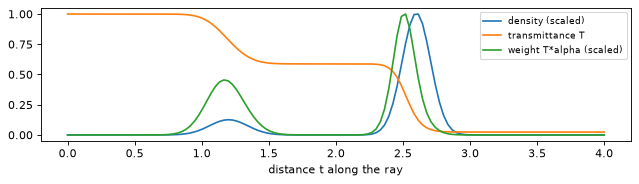

In [18]:
t = np.linspace(0, 4, 128); delta = t[1] - t[0]
sigma = 1.5 * np.exp(-((t - 1.2) / 0.2) ** 2) + 12.0 * np.exp(-((t - 2.6) / 0.15) ** 2)   # density along the ray
color = np.where(t[:, None] < 1.9, [1.0, 0.1, 0.1], [0.1, 0.2, 1.0])                     # red cloud, then blue object
alpha = 1 - np.exp(-sigma * delta)                       # chance the ray stops in each small segment
T = np.cumprod(np.r_[1.0, 1 - alpha[:-1]])               # transmittance: light still getting through
w = T * alpha                                            # contribution of each sample
pixel = (w[:, None] * color).sum(0)
print("pixel colour (R, G, B):", pixel.round(3), "| total opacity:", w.sum().round(3))
print("weight from red cloud:", w[t < 1.9].sum().round(3), "| weight from blue object:", w[t >= 1.9].sum().round(3))

fig, ax = plt.subplots(1, 1, figsize=(8, 2.4))
ax.plot(t, sigma / sigma.max(), label="density (scaled)"); ax.plot(t, T, label="transmittance T")
ax.plot(t, w / w.max(), label="weight T*alpha (scaled)"); ax.set_xlabel("distance t along the ray"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The faint red cloud tints the pixel a little, then the dense blue object absorbs almost all of the remaining light, so nothing behind it can contribute. Exactly the same weighting is used when NeRF is trained, with the network supplying $\sigma$ and $\mathbf c$. The full pipeline (positional encoding, hierarchical sampling, Instant-NGP, variants) is in [`../06_Computer_Vision/09_3d_vision.ipynb`](../06_Computer_Vision/09_3d_vision.ipynb).

### 6.2 Gaussian splatting (brief)

**3D Gaussian splatting** (Kerbl, Kopanas, Leimkuehler and Drettakis, 2023) represents a scene with millions of small, coloured, semi-transparent 3D **Gaussian blobs**, each with a centre, a shape (covariance $\Sigma = R S S^\top R^\top$, i.e. a rotation and three scales), an opacity and a view-dependent colour. To render, each blob is projected ("splatted") to the screen and blended front to back with the **same** formula $\sum_i T_i \alpha_i \mathbf c_i$. No network is queried per sample, so it renders in real time.

| | NeRF | 3D Gaussian splatting |
|---|---|---|
| Scene stored as | network weights (implicit) | a list of Gaussians (explicit) |
| Rendering | ray marching, many network calls per pixel | rasterisation of blobs, real time |
| Training speed | slow for the original, fast with hash grids | fast |
| Editing | hard | easier (move or delete blobs) |
| Memory | small | can be large (many blobs) |

**Used today (late 2026):** 3D capture for maps, real estate, film and games, robotics simulation, and digital twins; both NeRF-style and splatting methods, with splatting widely adopted for real-time viewing. **Limits:** need many well-posed photos with accurate camera poses; reflective, transparent and moving objects remain hard.

## 7. Equivariant and geometric networks

**Invariance vs equivariance.** Let $g$ be a transformation (shift, rotation, reordering).
- A function is **invariant** if transforming the input does not change the output: $f(g \cdot x) = f(x)$. Example: "is there a cat in this photo?" should not change if the photo is shifted.
- A function is **equivariant** if transforming the input transforms the output in the same way: $f(g \cdot x) = g \cdot f(x)$. Example: a segmentation mask should shift when the photo shifts.

**Simple analogy.** Invariance: your name does not change when you turn around. Equivariance: your shadow turns when you turn.

**Why build it in?** If a symmetry is guaranteed by the problem, a network that respects it by design does not waste data learning it, and it cannot get it wrong. This is the central idea of **geometric deep learning** (Bronstein, Bruna, Cohen and Velickovic, 2021): most successful architectures are "an MLP plus the right symmetry" on the right domain, which they summarise as the **5 Gs**: grids, groups, graphs, geodesics and gauges.

| Data | Symmetry | Architecture that respects it |
|---|---|---|
| images (grids) | translation | CNN (convolution is translation-equivariant) |
| sets, point clouds | permutation (order of elements) | Deep Sets, PointNet, transformers without positions |
| graphs | permutation of node labels | GNN (message passing) |
| images with no "up" (microscopy, satellite) | rotation, reflection | group-equivariant CNN, steerable CNN |
| molecules, 3D physics | rotation, translation, reflection: E(3) | E(3)-equivariant GNN (EGNN, NequIP, MACE) |
| time series | time shift | 1D convolution, TCN |

### 7.1 Deep Sets and PointNet: permutation invariance

**How it works.** For a set $X = \{x_1, \dots, x_N\}$, Deep Sets (Zaheer et al., 2017) proved that permutation-invariant functions can be written as

$$f(X) = \rho\Big(\textstyle\sum_{i=1}^{N} \phi(x_i)\Big),$$

i.e. apply the same small network $\phi$ to every element, combine with a **symmetric** operation (sum, mean or max), then apply another network $\rho$. **PointNet** (Qi et al., 2017) uses the same pattern with **max**-pooling for 3D point clouds. Because addition and max do not care about order, the output cannot depend on order. PointNet for LiDAR is built step by step in [`../26_Sensor_AI/04_lidar_point_clouds_from_zero.ipynb`](../26_Sensor_AI/04_lidar_point_clouds_from_zero.ipynb) and [`../06_Computer_Vision/09_3d_vision.ipynb`](../06_Computer_Vision/09_3d_vision.ipynb).

**Demo:** classify 2D point clouds as "circle outline" or "square outline" (random size, rotation and noise), then shuffle the points.

In [19]:
def make_shapes(n_sets, n_pts, rng):
    X, y = [], []
    for _ in range(n_sets):
        label = rng.integers(2)
        s = rng.uniform(0, 1, n_pts)
        if label == 0:                                            # circle outline
            pts = np.c_[np.cos(2 * np.pi * s), np.sin(2 * np.pi * s)]
        else:                                                     # square outline
            side, u = rng.integers(4, size=n_pts), 2 * s - 1
            pts = np.select([side[:, None] == k for k in range(4)],
                            [np.c_[u, np.ones_like(u)], np.c_[u, -np.ones_like(u)], np.c_[np.ones_like(u), u], np.c_[-np.ones_like(u), u]])
        a = rng.uniform(0, 2 * np.pi); R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
        X.append(rng.uniform(0.5, 1.5) * pts @ R.T + 0.03 * rng.standard_normal((n_pts, 2))); y.append(label)
    return torch.tensor(np.array(X), dtype=torch.float32), torch.tensor(y)

class DeepSet(nn.Module):
    def __init__(self, h=64):
        super().__init__()
        self.phi = mlp(2, h, width=h, depth=2, act=nn.ReLU)       # applied to every point separately
        self.rho = mlp(h, 2, width=h, depth=1, act=nn.ReLU)       # applied after pooling
    def forward(self, X):                                         # X: (batch, n_points, 2)
        return self.rho(self.phi(X).max(dim=1).values)            # max-pool over points (PointNet style)

rng = np.random.default_rng(0)
X_tr, y_tr = make_shapes(600, 32, rng); X_te, y_te = make_shapes(300, 32, rng)
seed_all()
models = {"Deep Set (max-pool)": DeepSet(), "MLP on flattened points": mlp(64, 2, width=64, depth=2, act=nn.ReLU)}
inputs = {"Deep Set (max-pool)": lambda X: X, "MLP on flattened points": lambda X: X.reshape(len(X), -1)}
perm = torch.randperm(32)
rows = []
for name, model in models.items():
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    for step in range(300):
        loss = F.cross_entropy(model(inputs[name](X_tr)), y_tr)
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        out = model(inputs[name](X_te)); out_perm = model(inputs[name](X_te[:, perm]))
    rows.append({"model": name, "test accuracy": (out.argmax(1) == y_te).float().mean().item(),
                 "accuracy after shuffling points": (out_perm.argmax(1) == y_te).float().mean().item(),
                 "max output change when shuffled": (out - out_perm).abs().max().item()})
print(pd.DataFrame(rows).round(4).to_string(index=False))

                  model  test accuracy  accuracy after shuffling points  max output change when shuffled
    Deep Set (max-pool)         1.0000                           1.0000                           0.0000
MLP on flattened points         0.5167                           0.4733                          26.2384


The Deep Set gives *exactly* the same output after shuffling (change 0), by construction, and it solves the task. The flattened MLP treats "point number 7" as a special input slot even though the points arrive in random order, so it barely beats guessing and its outputs change when the points are shuffled.

### 7.2 Group-equivariant CNNs: the rotation idea

A CNN shares one filter across all **positions**, which gives translation equivariance. A **group-equivariant CNN** (G-CNN; Cohen and Welling, 2016) also shares it across **rotations**: it applies every rotated copy of the filter. For the group $C_4$ of 90-degree rotations, the first ("lifting") layer is

$$[f \star \psi](\mathbf x, r) = \sum_{\mathbf y} f(\mathbf y)\,\big(\text{rot}^r \psi\big)(\mathbf y - \mathbf x), \qquad r \in \{0, 1, 2, 3\}.$$

Rotating the input image then *rotates each feature map and cyclically shifts the rotation channel*. Pooling over $r$ and over space gives a rotation-invariant output. Below we check this numerically.

In [20]:
seed_all()
image = torch.randn(1, 1, 15, 15)
psi = torch.randn(1, 1, 3, 3)                                  # a random (not symmetric) filter
rot = lambda z, k=1: torch.rot90(z, k, dims=(-2, -1))          # rotate by k * 90 degrees
conv = lambda z, w: F.conv2d(z, w, padding=1)

# 1) plain convolution: does rotating the input just rotate the output?
plain_err = (conv(rot(image), psi) - rot(conv(image, psi))).abs().max().item()

# 2) lifting group convolution over C4: one output channel per rotated copy of the filter
def lift_c4(z, w):
    return torch.cat([conv(z, rot(w, r)) for r in range(4)], dim=1)     # (1, 4, H, W)

out, out_rot = lift_c4(image, psi), lift_c4(rot(image), psi)
expected = rot(torch.roll(out, shifts=1, dims=1))              # rotate maps AND shift rotation channel
gcnn_err = (out_rot - expected).abs().max().item()

# 3) invariant output: pool over rotations and over space
inv = lambda o: o.max(dim=1).values.mean().item()
print(f"plain conv equivariance error  : {plain_err:.3f}  (large: plain CNNs are not rotation-equivariant)")
print(f"C4 group conv equivariance error: {gcnn_err:.2e} (zero up to float rounding)")
print(f"pooled output, original vs rotated input: {inv(out):.5f} vs {inv(out_rot):.5f}")

plain conv equivariance error  : 10.845  (large: plain CNNs are not rotation-equivariant)
C4 group conv equivariance error: 9.54e-07 (zero up to float rounding)
pooled output, original vs rotated input: 1.85498 vs 1.85498


**Used today:** medical and microscopy images, satellite and aerial imagery, and any data without a natural "up". Libraries such as `escnn` implement steerable CNNs for continuous rotations. **Limits:** more compute per layer, and if the task is *not* symmetric (a "6" vs a "9"), enforcing rotation invariance hurts.

### 7.3 E(3)-equivariant GNNs for molecules (brief)

A molecule's energy does not change if you rotate, move or mirror it (the group **E(3)**), while the forces on the atoms rotate with it (equivariance). **E(3)-equivariant GNNs** treat atoms as nodes with features $h_i$ and 3D positions $\mathbf x_i$. The simple **EGNN** layer (Satorras, Hoogeboom and Welling, 2021) uses only distances (which are invariant) to make messages, and moves positions only along relative vectors $\mathbf x_i - \mathbf x_j$ (which rotate correctly):

$$\mathbf m_{ij} = \phi_e\big(h_i, h_j, \|\mathbf x_i - \mathbf x_j\|^2\big),\qquad
\mathbf x_i' = \mathbf x_i + \tfrac{1}{N-1}\sum_{j\ne i} (\mathbf x_i - \mathbf x_j)\,\phi_x(\mathbf m_{ij}),\qquad
h_i' = h_i + \phi_h\big(h_i, \textstyle\sum_{j} \mathbf m_{ij}\big).$$

In [21]:
class EGNNLayer(nn.Module):
    def __init__(self, h_dim=8, m_dim=16):
        super().__init__()
        self.phi_e = nn.Sequential(nn.Linear(2 * h_dim + 1, m_dim), nn.SiLU(), nn.Linear(m_dim, m_dim), nn.SiLU())
        self.phi_x = nn.Sequential(nn.Linear(m_dim, m_dim), nn.SiLU(), nn.Linear(m_dim, 1))
        self.phi_h = nn.Sequential(nn.Linear(h_dim + m_dim, m_dim), nn.SiLU(), nn.Linear(m_dim, h_dim))
    def forward(self, h, x):                       # h: (N, h_dim) atom features, x: (N, 3) positions
        N = h.shape[0]
        diff = x[:, None, :] - x[None, :, :]       # (N, N, 3) relative vectors
        dist2 = (diff ** 2).sum(-1, keepdim=True)  # (N, N, 1) squared distances: rotation-invariant
        mask = 1 - torch.eye(N).unsqueeze(-1)      # no self-messages
        m = self.phi_e(torch.cat([h[:, None].expand(N, N, -1), h[None].expand(N, N, -1), dist2], -1)) * mask
        x_new = x + (diff * self.phi_x(m) * mask).sum(1) / (N - 1)
        h_new = h + self.phi_h(torch.cat([h, m.sum(1)], -1))
        return h_new, x_new

seed_all()
layer = EGNNLayer()
h0, x0 = torch.randn(6, 8), torch.randn(6, 3)                  # a toy "molecule" with 6 atoms
Q, _ = torch.linalg.qr(torch.randn(3, 3))                      # random orthogonal matrix (rotation or reflection)
shift = torch.randn(1, 3)
h1, x1 = layer(h0, x0)
h2, x2 = layer(h0, x0 @ Q.T + shift)                           # rotate + translate the input molecule
print("features invariant?   max |h(gx) - h(x)|      =", f"{(h2 - h1).abs().max().item():.1e}")
print("positions equivariant? max |x(gx) - g x(x)|   =", f"{(x2 - (x1 @ Q.T + shift)).abs().max().item():.1e}")
plain = mlp(18, 8, width=16, depth=1)
print("plain MLP on raw coordinates changes by       =", f"{(plain(x0.reshape(1, -1)) - plain((x0 @ Q.T + shift).reshape(1, -1))).abs().max().item():.2f}")

features invariant?   max |h(gx) - h(x)|      = 1.2e-07
positions equivariant? max |x(gx) - g x(x)|   = 1.2e-07
plain MLP on raw coordinates changes by       = 0.44


**Used today:** machine-learned interatomic potentials (NequIP, MACE, Allegro use higher-order tensor features), molecular property prediction (SchNet, DimeNet), molecule and protein generation (equivariant diffusion), and protein structure prediction (AlphaFold 2's structure module uses invariant point attention). Graph neural networks in general are covered in [`07_gnn.ipynb`](07_gnn.ipynb) and [`21_graph_machine_learning_hands_on.ipynb`](21_graph_machine_learning_hands_on.ipynb). **Limits:** higher-order equivariant models are expensive, and fully connected message passing scales as $N^2$, so real models use a distance cutoff.

## 8. Sequence architectures beyond RNNs

RNNs, LSTMs, GRUs and attention are built hands-on in [`19_sequence_models_hands_on.ipynb`](19_sequence_models_hands_on.ipynb). Their weakness: they process one step at a time, so training cannot be parallelised over the sequence. Transformers fix that but cost $O(T^2)$ in sequence length $T$. The families below try to get **parallel training** and **cheap long-range memory** together.

### 8.1 Temporal convolutional networks (TCN) and WaveNet

**What it is.** A TCN (Bai, Kolter and Koltun, 2018) is a stack of 1D convolutions over time with two rules:
- **causal**: the output at time $t$ only uses inputs at times $\le t$ (pad only on the left, never peek at the future);
- **dilated**: layer $l$ skips $d_l - 1$ inputs between filter taps, with $d_l = 1, 2, 4, 8, \dots$, so the view grows exponentially with depth.

**WaveNet** (van den Oord et al., 2016) used exactly this to generate raw audio one sample at a time, with gated activations $\tanh(W_f * x) \odot \sigma(W_g * x)$ and residual/skip connections.

$$y_t = \sum_{i=0}^{k-1} w_i\, x_{t - d\cdot i}, \qquad \text{receptive field } R = 1 + (k-1)\sum_{l} d_l \ \ (\text{per conv layer}).$$

In words: the **receptive field** is how far back in time one output can "see". With kernel size $k=2$ and dilations $1, 2, \dots, 512$, one output sees $1024$ past samples after only 10 layers.

```text
dilation 4:  o . . . o . . . o          output at t
dilation 2:  o . o . o . o . o
dilation 1:  o o o o o o o o o
input:       x x x x x x x x x   <- only the past is used
```

In [22]:
def receptive_field(kernel_size, dilations, convs_per_block=1):
    # how many past time steps (including the current one) one output can depend on
    return 1 + convs_per_block * (kernel_size - 1) * sum(dilations)

configs = {
    "5 layers, k=2, no dilation":               (2, [1] * 5, 1),
    "5 layers, k=2, dilations 1..16":           (2, [1, 2, 4, 8, 16], 1),
    "WaveNet stack: k=2, dilations 1..512":     (2, [2 ** i for i in range(10)], 1),
    "WaveNet, 3 stacks of 1..512":              (2, [2 ** i for i in range(10)] * 3, 1),
    "TCN: k=3, blocks with d=1..8, 2 convs/blk":(3, [1, 2, 4, 8], 2),
}
print(pd.DataFrame([{"config": k, "receptive field": receptive_field(*v)} for k, v in configs.items()]).to_string(index=False))

                                   config  receptive field
               5 layers, k=2, no dilation                6
           5 layers, k=2, dilations 1..16               32
     WaveNet stack: k=2, dilations 1..512             1024
              WaveNet, 3 stacks of 1..512             3070
TCN: k=3, blocks with d=1..8, 2 convs/blk               61


In [23]:
class CausalConv1d(nn.Module):
    def __init__(self, c_in, c_out, k, dilation):
        super().__init__()
        self.pad = (k - 1) * dilation                       # pad on the LEFT only, so no future leaks in
        self.conv = nn.Conv1d(c_in, c_out, k, dilation=dilation)
    def forward(self, x):
        return self.conv(F.pad(x, (self.pad, 0)))

class TinyTCN(nn.Module):
    def __init__(self, dilations, ch=16, k=2):
        super().__init__()
        self.inp = nn.Conv1d(1, ch, 1)
        self.layers = nn.ModuleList([CausalConv1d(ch, ch, k, d) for d in dilations])
        self.out = nn.Conv1d(ch, 1, 1)
    def forward(self, x):                                    # x: (batch, 1, T)
        h = self.inp(x)
        for layer in self.layers:
            h = h + F.relu(layer(h))                         # residual connection
        return self.out(h)

# Task: delayed copy. Output at time t must equal the input at time t - 20.
DELAY, T_LEN = 20, 64
def copy_batch(b, g):
    x = torch.randn(b, 1, T_LEN, generator=g)
    y = torch.zeros_like(x); y[:, :, DELAY:] = x[:, :, :-DELAY]
    return x, y

rows = []
for name, dil in [("no dilation (RF 6)", [1] * 5), ("dilations 1..16 (RF 32)", [1, 2, 4, 8, 16])]:
    seed_all(); g = torch.Generator().manual_seed(0)
    tcn = TinyTCN(dil); opt = torch.optim.Adam(tcn.parameters(), lr=3e-3)
    for step in range(400):
        x, y = copy_batch(32, g)
        loss = (tcn(x)[:, :, DELAY:] - y[:, :, DELAY:]).pow(2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    x, y = copy_batch(256, g)
    with torch.no_grad():
        test = (tcn(x)[:, :, DELAY:] - y[:, :, DELAY:]).pow(2).mean().item()
    rows.append({"model": name, "test MSE (1.0 = no better than guessing 0)": round(test, 4)})
print(pd.DataFrame(rows).to_string(index=False))

# causality check: change the input at t = 40; outputs before t = 40 must not change
x = torch.randn(1, 1, T_LEN); x2 = x.clone(); x2[0, 0, 40] += 5.0
with torch.no_grad():
    d = (tcn(x) - tcn(x2)).abs()[0, 0]
print("max change in outputs before t=40:", d[:40].max().item(), "| at t>=40:", round(d[40:].max().item(), 3))

                  model  test MSE (1.0 = no better than guessing 0)
     no dilation (RF 6)                                      1.0019
dilations 1..16 (RF 32)                                      0.0004
max change in outputs before t=40: 0.0 | at t>=40: 4.987


Only the dilated TCN can see 20 steps back, so only it solves the task; the causality check confirms that the future never leaks into the past.

**Used today:** audio generation and speech (WaveNet-style vocoders, though many now use GANs, flows or diffusion), sensor and industrial time series, forecasting baselines (see [`../04_Forecasting/04_deep_learning_forecasting.ipynb`](../04_Forecasting/04_deep_learning_forecasting.ipynb)). **Limits:** the receptive field is fixed by design (nothing beyond it can be used), and generation is still one step at a time.

### 8.2 State-space models (SSM) and Mamba

**What it is.** A linear **state-space model** comes from control theory. A hidden state $h$ (a vector of size $N$) summarises the past:

$$h'(t) = A\,h(t) + B\,x(t), \qquad y(t) = C\,h(t).$$

To use it on a sequence with step size $\Delta$ we **discretise** it. With the zero-order hold (ZOH) rule, $\bar A = e^{\Delta A}$ and $\bar B = (\Delta A)^{-1}(e^{\Delta A} - I)\,\Delta B$, giving a **recurrence**:

$$h_t = \bar A\,h_{t-1} + \bar B\,x_t, \qquad y_t = C\,h_t .$$

Unroll it and you get a **convolution** with a fixed kernel:

$$y_t = \sum_{k=0}^{t} \underbrace{C\,\bar A^{k}\,\bar B}_{\bar K_k}\; x_{t-k}, \qquad \bar K = \big(C\bar B,\ C\bar A\bar B,\ C\bar A^2\bar B,\ \dots\big).$$

That duality is the key trick of S4 (Gu, Goel and Re, 2022): **train as a convolution** (parallel, fast with FFT), **run as a recurrence** (constant memory per new token, like an RNN). Let us check that both forms give the same numbers.

In [24]:
rng = np.random.default_rng(0)
N_STATE, L = 4, 50
A = -np.array([0.5, 1.0, 2.0, 4.0])          # diagonal A (negative = stable, memories fade)
Bv, Cv, dt = np.ones(N_STATE), rng.standard_normal(N_STATE), 0.1
A_bar = np.exp(dt * A)                       # ZOH for a diagonal A, element-wise
B_bar = (A_bar - 1) / A * Bv
x_seq = rng.standard_normal(L)

# form 1: recurrence (how it runs at inference, one token at a time)
h, y_rec = np.zeros(N_STATE), []
for xt in x_seq:
    h = A_bar * h + B_bar * xt
    y_rec.append(Cv @ h)

# form 2: convolution with kernel K_k = C A_bar^k B_bar (how it can be trained, all tokens at once)
K_kernel = np.array([Cv @ (A_bar ** k * B_bar) for k in range(L)])
y_conv = np.array([np.sum(K_kernel[:t + 1][::-1] * x_seq[:t + 1]) for t in range(L)])
print("max |recurrence - convolution| =", np.abs(np.array(y_rec) - y_conv).max())

max |recurrence - convolution| = 1.1102230246251565e-16


**The selective idea (Mamba).** In S4, $\Delta$, $B$ and $C$ are the same for every token, so the model treats all tokens alike. **Mamba** (Gu and Dao, 2023) makes them **depend on the current input**: $\Delta_t, B_t, C_t = f(x_t)$. A large $\Delta_t$ means "reset and write this token into memory"; a tiny $\Delta_t$ means $\bar A_t \approx I$ and $\bar B_t \approx 0$: "ignore this token and keep the memory as it is". This lets the model **select** what to remember, like an LSTM gate. The price: the kernel is no longer fixed, so the convolution trick is gone; Mamba instead uses a hardware-aware **parallel scan** (the recurrence is associative, so it can be computed in a tree in $O(\log T)$ parallel steps).

Toy demo: one important token at $t = 0$, followed by 199 filler tokens of random noise. Can the state still remember the important value at the end?

In [25]:
rng = np.random.default_rng(0)
T_seq = 200
x_tok = np.r_[1.0, 0.3 * rng.standard_normal(T_seq - 1)]      # important value 1.0, then noise
is_important = np.r_[True, np.zeros(T_seq - 1, bool)]
a = -1.0                                                       # one-dimensional state, A = -1

def run_ssm(deltas):
    h, hist = 0.0, []
    for xt, d in zip(x_tok, deltas):
        A_b = np.exp(d * a); B_b = (A_b - 1) / a              # ZOH with this token's step size
        h = A_b * h + B_b * xt
        hist.append(h)
    return np.array(hist)

fixed = run_ssm(np.full(T_seq, 0.1))                           # S4-style: same step for every token
selective = run_ssm(np.where(is_important, 3.0, 1e-4))          # Mamba-style: step chosen per token
print(f"state at the end, fixed step     : {fixed[-1]:+.3f}  (memory of the important token has faded)")
print(f"state at the end, selective step : {selective[-1]:+.3f}  (the value written at t=0 was {selective[0]:+.3f})")

state at the end, fixed step     : -0.056  (memory of the important token has faded)
state at the end, selective step : +0.932  (the value written at t=0 was +0.950)


(In the real Mamba the step sizes are *learned* functions of the token, not set by hand as here.) The full story, including S4, Mamba-2 and hybrid transformer-SSM models, is in [`../08_LLM/14_llm_architecture_innovations.ipynb`](../08_LLM/14_llm_architecture_innovations.ipynb).

**Used today (late 2026):** long-sequence modelling (genomics, audio, long documents), and **hybrid** language models that interleave a few attention layers with many SSM layers to cut memory at long context. **Limits:** a fixed-size state must compress the whole past, so pure SSMs are weaker than attention at exact recall and copying from far back; hence the hybrids.

### 8.3 Linear attention and RWKV (brief)

Softmax attention compares every query with every key: $O(T^2)$. **Linear attention** (Katharopoulos et al., 2020) replaces $\exp(q^\top k)$ with a feature-map product $\phi(q)^\top\phi(k)$, which lets us regroup the sum:

$$y_t = \frac{\phi(q_t)^\top \sum_{s\le t}\phi(k_s)\,v_s^\top}{\phi(q_t)^\top \sum_{s \le t}\phi(k_s)} = \frac{\phi(q_t)^\top S_t}{\phi(q_t)^\top z_t}, \qquad S_t = S_{t-1} + \phi(k_t)\,v_t^\top,\quad z_t = z_{t-1} + \phi(k_t).$$

In words: a causal linear-attention layer **is an RNN** whose state is a matrix $S_t$. **RWKV** (Peng et al., 2023) and **RetNet** (Sun et al., 2023) add a learned **decay** so old information fades, and newer variants (gated linear attention, DeltaNet, RWKV-7) add input-dependent gates, which brings them very close to selective SSMs. A quick numerical check of the two forms:

In [26]:
rng = np.random.default_rng(0)
Tq, dk, dv = 6, 4, 3
Q, Kk, V = rng.standard_normal((Tq, dk)), rng.standard_normal((Tq, dk)), rng.standard_normal((Tq, dv))
phi = lambda z: np.where(z > 0, z + 1, np.exp(z))          # elu(z) + 1: keeps features positive

# parallel form (like attention, all pairs s <= t)
scores = np.tril(phi(Q) @ phi(Kk).T)                        # causal mask
y_parallel = (scores @ V) / scores.sum(1, keepdims=True)

# recurrent form (constant-size state, one token at a time)
S, z, y_rec = np.zeros((dk, dv)), np.zeros(dk), []
for t in range(Tq):
    S += np.outer(phi(Kk[t]), V[t]); z += phi(Kk[t])
    y_rec.append(phi(Q[t]) @ S / (phi(Q[t]) @ z))
print("max |parallel - recurrent| =", np.abs(y_parallel - np.array(y_rec)).max())

max |parallel - recurrent| = 4.440892098500626e-16


### 8.4 xLSTM (brief)

**xLSTM** (Beck et al., 2024) revisits the LSTM with two changes: **exponential gating** (gates can grow large, with a normaliser state to keep values stable) and new memory types. The **sLSTM** keeps a scalar memory with new mixing between heads; the **mLSTM** stores a **matrix memory** $C_t = f_t C_{t-1} + i_t\, v_t k_t^\top$ (very like linear attention with gates) and can be trained in parallel. It shows that the recurrent idea is competitive again when given modern gating and parallel training.

### 8.5 Which sequence model?

| Model | Training parallel over time? | Cost per new token at inference | Memory of the past | Typical use today |
|---|---|---|---|---|
| RNN / LSTM / GRU | no | constant | fixed-size state, fades | small on-device models, streaming sensors |
| TCN / WaveNet | yes | grows with receptive field (cacheable) | fixed window (receptive field) | audio, sensor time series |
| Transformer | yes | grows with context (KV cache) | exact, everything in the window | language, vision, almost everything |
| SSM / Mamba | yes (convolution or scan) | constant | fixed-size state, selective | long sequences, hybrids with attention |
| Linear attention / RWKV / RetNet | yes | constant | matrix state with decay | efficient LLM alternatives |
| xLSTM | yes (mLSTM) | constant | matrix memory with gates | research, efficient LLM alternatives |

## 9. Vision architecture lineage

Convolutions, pooling and a first ResNet are taught in [`03_cnn.ipynb`](03_cnn.ipynb) and [`../06_Computer_Vision/00_start_here_images_and_your_first_cnn.ipynb`](../06_Computer_Vision/00_start_here_images_and_your_first_cnn.ipynb); vision transformers in [`../06_Computer_Vision/05_vision_transformers.ipynb`](../06_Computer_Vision/05_vision_transformers.ipynb). Here is the family tree, with the one idea each generation added.

```mermaid
flowchart LR
    A[LeNet-5 1998] --> B[AlexNet 2012] --> C[VGG 2014] --> E[ResNet 2015]
    B --> D[Inception 2014] --> E
    E --> F[DenseNet 2017]
    E --> G[MobileNet 2017] --> H[EfficientNet 2019]
    E --> I[ViT 2020] --> J[ConvNeXt 2022]
    E --> J
    E --> U[U-Net 2015<br/>encoder-decoder]
```

| Network | Year | The key idea, in simple words | Key maths / design |
|---|---|---|---|
| **LeNet-5** (LeCun et al.) | 1998 | convolution + pooling + small classifier for handwritten digits | conv, subsampling, tanh |
| **AlexNet** (Krizhevsky, Sutskever, Hinton) | 2012 | a much bigger CNN trained on GPUs; won ImageNet by a large margin and started the deep-learning boom | ReLU, dropout, data augmentation |
| **VGG** (Simonyan, Zisserman) | 2014 | use only small 3x3 filters, stacked deep | two 3x3 convs see 5x5 with fewer weights: $2 \cdot 9C^2 < 25C^2$ |
| **Inception / GoogLeNet** (Szegedy et al.) | 2014 | run 1x1, 3x3, 5x5 filters in parallel and concatenate; 1x1 "bottleneck" convs cut cost | multi-branch blocks, 1x1 convs |
| **ResNet** (He et al.) | 2015 | skip connections let very deep nets (100+ layers) train | $y = x + F(x)$: the block only learns a correction |
| **U-Net** (Ronneberger et al.) | 2015 | encoder shrinks, decoder grows back, skip connections carry fine detail across; for per-pixel outputs | see below |
| **DenseNet** (Huang et al.) | 2017 | each layer receives the outputs of **all** previous layers | $x_l = H_l([x_0, x_1, \dots, x_{l-1}])$ |
| **MobileNet** (Howard et al.) | 2017 | depthwise separable convs for phones | $k^2C + C^2$ instead of $k^2C^2$ weights |
| **EfficientNet** (Tan, Le) | 2019 | scale depth, width and input resolution **together** with one knob $\phi$ | $d=\alpha^\phi,\ w=\beta^\phi,\ r=\gamma^\phi$ with $\alpha\beta^2\gamma^2 \approx 2$ |
| **ViT** (Dosovitskiy et al.) | 2020 | cut the image into 16x16 patches, treat them as tokens, use a plain transformer | patch embedding + self-attention |
| **ConvNeXt** (Liu et al.) | 2022 | modernise a ResNet with transformer-era choices; a pure CNN that matches ViTs | 7x7 depthwise convs, LayerNorm, GELU, inverted bottleneck |

**As of late 2026**, typical choices are ViT-style backbones pre-trained with self-supervision (see [`09_self_supervised_learning.ipynb`](09_self_supervised_learning.ipynb)) for large models, and ConvNeXt, EfficientNet or MobileNet-style CNNs where speed and small data matter. The design ideas are easier to remember as weight counts:

In [27]:
C = 256
rows = [
    ("one 5x5 conv, C->C",                          25 * C * C),
    ("two 3x3 convs, C->C (VGG idea)",              2 * 9 * C * C),
    ("5x5 conv 256->64 directly",                   25 * 256 * 64),
    ("1x1 to 32, then 5x5 32->64 (Inception idea)", 256 * 32 + 25 * 32 * 64),
    ("standard 3x3 conv, C->C",                     9 * C * C),
    ("depthwise 3x3 + pointwise 1x1 (MobileNet)",   9 * C + C * C),
    ("ConvNeXt-style depthwise 7x7 + 1x1s (4x)",    49 * C + 2 * 4 * C * C),
]
print(pd.DataFrame(rows, columns=["layer design (bias ignored)", "weights"]).to_string(index=False))

                layer design (bias ignored)  weights
                         one 5x5 conv, C->C  1638400
             two 3x3 convs, C->C (VGG idea)  1179648
                  5x5 conv 256->64 directly   409600
1x1 to 32, then 5x5 32->64 (Inception idea)    59392
                    standard 3x3 conv, C->C   589824
  depthwise 3x3 + pointwise 1x1 (MobileNet)    67840
   ConvNeXt-style depthwise 7x7 + 1x1s (4x)   536832


### 9.1 U-Net: encoder-decoder with skip connections

**What it is.** U-Net (Ronneberger, Fischer and Brox, 2015) outputs one value **per pixel** (segmentation, denoising). The **encoder** (left side of the "U") repeatedly convolves and halves the resolution to understand *what* is in the image; the **decoder** (right side) upsamples back to full size to say *where*. **Skip connections** copy each encoder feature map across to the matching decoder stage, so fine detail lost by downsampling comes back.

**Simple analogy.** Summarising a long report (encoder), then rewriting it in full while glancing at your original notes for exact details (skip connections).

**Used today:** medical image segmentation (see [`../06_Computer_Vision/10_medical_image_analysis.ipynb`](../06_Computer_Vision/10_medical_image_analysis.ipynb)), the denoising network inside many diffusion image generators, satellite and defect segmentation. **Limits:** memory heavy at high resolution; global context is limited unless attention blocks are added.

In [28]:
def double_conv(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.ReLU(), nn.Conv2d(c_out, c_out, 3, padding=1), nn.ReLU())

class TinyUNet(nn.Module):
    def __init__(self, c=8):
        super().__init__()
        self.enc1, self.enc2, self.bottom = double_conv(1, c), double_conv(c, 2 * c), double_conv(2 * c, 4 * c)
        self.up2, self.dec2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2), double_conv(4 * c, 2 * c)
        self.up1, self.dec1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2), double_conv(2 * c, c)
        self.head = nn.Conv2d(c, 1, 1)                     # one output value per pixel
    def forward(self, x, show=False):
        e1 = self.enc1(x)                                  # full resolution
        e2 = self.enc2(F.max_pool2d(e1, 2))                # 1/2 resolution
        b = self.bottom(F.max_pool2d(e2, 2))               # 1/4 resolution, most channels
        u2 = self.up2(b); d2 = self.dec2(torch.cat([u2, e2], dim=1))   # skip connection from e2
        u1 = self.up1(d2); d1 = self.dec1(torch.cat([u1, e1], dim=1))  # skip connection from e1
        out = self.head(d1)
        if show:
            for name, t in [("input", x), ("enc1", e1), ("enc2", e2), ("bottleneck", b), ("up2", u2),
                            ("cat(up2, enc2) -> dec2", d2), ("up1", u1), ("cat(up1, enc1) -> dec1", d1), ("output", out)]:
                print(f"{name:26s} {tuple(t.shape)}")
        return out

unet = TinyUNet()
_ = unet(torch.randn(1, 1, 64, 64), show=True)
print("parameters:", n_params(unet))

input                      (1, 1, 64, 64)
enc1                       (1, 8, 64, 64)
enc2                       (1, 16, 32, 32)
bottleneck                 (1, 32, 16, 16)
up2                        (1, 16, 32, 32)
cat(up2, enc2) -> dec2     (1, 16, 32, 32)
up1                        (1, 8, 64, 64)
cat(up1, enc1) -> dec1     (1, 8, 64, 64)
output                     (1, 1, 64, 64)
parameters: 29321


### 9.2 Object detection families (brief)

Detection means finding **boxes plus labels**. Details and demos are in [`../06_Computer_Vision/03_object_detection.ipynb`](../06_Computer_Vision/03_object_detection.ipynb) and segmentation in [`../06_Computer_Vision/04_image_segmentation.ipynb`](../06_Computer_Vision/04_image_segmentation.ipynb).

| Family | Examples | Idea | Trade-off |
|---|---|---|---|
| Two-stage | R-CNN, Fast/Faster R-CNN, Mask R-CNN | propose candidate regions, then classify and refine each | accurate, slower |
| One-stage, anchor-based | SSD, RetinaNet (focal loss), early YOLO versions | predict boxes from a dense grid of preset "anchor" boxes in one pass | fast |
| Anchor-free | FCOS, CenterNet, recent YOLO versions | predict object centres or distances to box edges directly | simpler, fast |
| Transformer-based | DETR, Deformable DETR, RT-DETR | a set of learned queries, each outputs one box; matched to ground truth by the Hungarian algorithm, no non-max suppression | elegant, end-to-end |
| Open-vocabulary | OWL-ViT, Grounding DINO | detect objects named by a text prompt | flexible, heavier |
| Promptable segmentation | SAM family | segment anything given a click, box or text | general purpose masks |

## 10. Conditional computation and efficiency

**The idea.** A normal network uses *every* weight for *every* input. Conditional computation uses only the part that is needed: more capacity without proportionally more compute.

### 10.1 Mixture of Experts (MoE)

**What it is.** Replace one big feed-forward block with $E$ smaller "expert" blocks and a **router** (gate) that picks the top-$k$ experts for each token:

$$y = \sum_{i \in \text{TopK}(g(x))} \text{softmax}\big(g(x)\big)_i\; E_i(x), \qquad g(x) = W_g x .$$

**Simple analogy.** A hospital triage desk: each patient sees the one or two specialists they need, not every doctor. The hospital can employ many specialists while each visit stays short.

The main practical problem is **load balancing**: the router tends to send everything to a few favourite experts. A common fix (Switch Transformer, Fedus et al., 2022) adds an auxiliary loss $\mathcal{L}_{\text{aux}} = E\sum_i f_i P_i$, where $f_i$ is the fraction of tokens sent to expert $i$ and $P_i$ the average router probability for it; it is smallest when the load is even. Newer models also use bias-based balancing without an extra loss.

In [29]:
rng = np.random.default_rng(0)
n_tok, d_model, E, top_k = 2000, 16, 8, 2
X_tok = rng.standard_normal((n_tok, d_model))

def route(W_g):
    logits = X_tok @ W_g
    top = np.argsort(-logits, axis=1)[:, :top_k]                          # chosen experts per token
    probs = np.exp(logits - logits.max(1, keepdims=True)); probs /= probs.sum(1, keepdims=True)
    f = np.bincount(top.ravel(), minlength=E) / (n_tok * top_k)          # fraction of assignments
    P = probs.mean(0)                                                     # mean router probability
    return np.bincount(top.ravel(), minlength=E), E * np.sum(f * P)

W_good = 0.3 * rng.standard_normal((d_model, E))
W_bad = 0.3 * W_good; W_bad[:, 0] += 2.0; W_bad[:, 1] += 1.5            # router that favours experts 0 and 1
for name, W_ in [("balanced router", W_good), ("collapsing router", W_bad)]:
    counts, aux = route(W_)
    print(f"{name:18s} tokens per expert {counts.tolist()}  aux loss {aux:.3f}  (1.0 = perfectly even)")

balanced router    tokens per expert [617, 401, 480, 543, 385, 660, 400, 514]  aux loss 1.032  (1.0 = perfectly even)
collapsing router  tokens per expert [985, 968, 409, 237, 380, 420, 243, 358]  aux loss 1.264  (1.0 = perfectly even)


MoE layers inside LLMs (top-k routing, expert parallelism, shared experts, fine-grained experts) are covered in [`../08_LLM/14_llm_architecture_innovations.ipynb`](../08_LLM/14_llm_architecture_innovations.ipynb) and the maths-and-code walkthrough [`../08_LLM/30_transformer_and_llm_mechanics_math_and_code.ipynb`](../08_LLM/30_transformer_and_llm_mechanics_math_and_code.ipynb). **Used today:** many of the largest open and closed LLMs (as of late 2026) are MoE models. **Limits:** all experts must sit in memory even though few are used per token; routing adds communication cost across devices; training can be unstable.

### 10.2 Early-exit networks

**What it is.** Attach small classifier heads after intermediate layers. At inference, if a head is already confident (max probability above a threshold $\tau$), stop there. Easy inputs exit early; hard ones go deeper. Examples: BranchyNet, multi-scale DenseNet, early-exit BERT variants; the same "skip work when easy" idea appears as layer skipping and speculative decoding in LLMs.

In [30]:
from sklearn.datasets import load_digits                 # small 8x8 digits dataset bundled with scikit-learn
from sklearn.model_selection import train_test_split
Xd, yd = load_digits(return_X_y=True)
Xd = Xd / 16.0
Xa, Xb, ya, yb = train_test_split(Xd, yd, test_size=0.3, random_state=0)
Xa, Xb = torch.tensor(Xa, dtype=torch.float32), torch.tensor(Xb, dtype=torch.float32)
ya, yb = torch.tensor(ya), torch.tensor(yb)

class EarlyExitNet(nn.Module):
    def __init__(self, h=64, n_blocks=3):
        super().__init__()
        self.blocks = nn.ModuleList([nn.Sequential(nn.Linear(64 if i == 0 else h, h), nn.ReLU()) for i in range(n_blocks)])
        self.heads = nn.ModuleList([nn.Linear(h, 10) for _ in range(n_blocks)])    # one classifier per depth
    def forward(self, x):
        outs = []
        for blk, head in zip(self.blocks, self.heads):
            x = blk(x); outs.append(head(x))
        return outs

seed_all()
ee = EarlyExitNet(); opt = torch.optim.Adam(ee.parameters(), lr=3e-3)
for epoch in range(200):                                  # train all heads together (sum of losses)
    loss = sum(F.cross_entropy(o, ya) for o in ee(Xa))
    opt.zero_grad(); loss.backward(); opt.step()

with torch.no_grad():
    probs = [F.softmax(o, 1) for o in ee(Xb)]
rows = []
for tau in [0.5, 0.9, 0.99, 1.01]:                        # 1.01 = never exit early
    exit_at = torch.full((len(yb),), 2); pred = probs[2].argmax(1).clone()
    for depth in [1, 0]:                                  # earliest confident head wins
        conf, p = probs[depth].max(1)
        take = conf >= tau
        exit_at[take] = depth; pred[take] = p[take]
    rows.append({"threshold tau": tau, "accuracy": (pred == yb).float().mean().item(),
                 "average blocks used (of 3)": (exit_at + 1).float().mean().item()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 threshold tau  accuracy  average blocks used (of 3)
          0.50     0.972                       1.017
          0.90     0.967                       1.274
          0.99     0.967                       1.765
          1.01     0.967                       3.000


On this easy dataset even the first head is about as accurate as the last, so most inputs can leave after one block at no real cost. On harder data the trade-off is real: a lower threshold saves compute but costs some accuracy, a higher one does the reverse. **Limits:** helps latency per input but complicates batching (inputs in a batch exit at different depths), and the confidence of early heads must be calibrated.

### 10.3 Sparse networks and the lottery ticket hypothesis (brief)

**Pruning** removes weights (sets them to zero), usually those with the smallest magnitude. Most trained networks can lose a large fraction of their weights with little accuracy loss after a short fine-tune. The **lottery ticket hypothesis** (Frankle and Carbin, 2019) says that a randomly initialised dense network contains a small sub-network (a "winning ticket") that, **trained in isolation from its original initial weights**, reaches similar accuracy; the evidence is that re-training the pruned mask from the *original* initial values tends to beat re-training it from *new* random values. Later work found that for big networks you must "rewind" to weights from early in training rather than the very start.

The demo below prunes 90% of an MLP's weights, then compares the three standard options. On a problem this small the gap between the last two rows is often small, so treat it as an illustration of the procedure, not proof.

In [31]:
def digits_mlp():
    return nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))

def train_masked(net, masks=None, epochs=150):
    opt = torch.optim.Adam(net.parameters(), lr=3e-3)
    for _ in range(epochs):
        loss = F.cross_entropy(net(Xa), ya)
        opt.zero_grad(); loss.backward(); opt.step()
        if masks:                                      # keep pruned weights at exactly zero
            with torch.no_grad():
                for p, m in masks.items(): p.mul_(m)
    with torch.no_grad():
        return (net(Xb).argmax(1) == yb).float().mean().item()

def accuracy(net):
    with torch.no_grad():
        return (net(Xb).argmax(1) == yb).float().mean().item()

def apply_masks(net, mask_list):
    ws = [m.weight for m in net if isinstance(m, nn.Linear)]
    with torch.no_grad():
        for w, m in zip(ws, mask_list): w.mul_(m)
    return dict(zip(ws, mask_list))

seed_all()
dense = digits_mlp(); init_state = {k: v.clone() for k, v in dense.state_dict().items()}
acc_dense = train_masked(dense)

# global magnitude pruning: keep the 10% largest weights (biases are kept)
weights = [m.weight for m in dense if isinstance(m, nn.Linear)]
threshold = torch.cat([w.detach().abs().ravel() for w in weights]).quantile(0.90)
mask_list = [(w.detach().abs() > threshold).float() for w in weights]

pruned = digits_mlp(); pruned.load_state_dict(dense.state_dict()); apply_masks(pruned, mask_list)
acc_pruned_no_retrain = accuracy(pruned)

ticket = digits_mlp(); ticket.load_state_dict(init_state)            # rewind survivors to ORIGINAL init
acc_ticket = train_masked(ticket, apply_masks(ticket, mask_list))

torch.manual_seed(123); random_init = digits_mlp()                    # same mask, NEW random init
acc_random = train_masked(random_init, apply_masks(random_init, mask_list))

print(pd.DataFrame({"test accuracy": [acc_dense, acc_pruned_no_retrain, acc_ticket, acc_random]},
                   index=["dense network (100% weights)", "pruned to 10%, no retraining",
                          "10% mask, rewound to original init, retrained", "10% mask, new random init, retrained"]).round(3))

                                               test accuracy
dense network (100% weights)                           0.967
pruned to 10%, no retraining                           0.133
10% mask, rewound to original init, retrained          0.950
10% mask, new random init, retrained                   0.909


Sparse networks are covered in practice (structured vs unstructured pruning, distillation, quantisation) in [`08_model_compression.ipynb`](08_model_compression.ipynb) and [`13_quantization_and_compression_advanced.ipynb`](13_quantization_and_compression_advanced.ipynb). **Limits:** unstructured sparsity rarely speeds things up on ordinary hardware unless it follows a supported pattern (for example 2:4 sparsity on some GPUs); finding tickets by repeated training is expensive.

## 11. World models, JEPA and diffusion transformers (brief)

**World models.** A world model is a network that learns *how the environment changes*: given the current state and an action, predict the next state, $\hat s_{t+1} = f_\theta(s_t, a_t)$. An agent can then **plan inside its own imagination** instead of trying everything in the real world. Examples: the "World Models" paper (Ha and Schmidhuber, 2018), the Dreamer family in reinforcement learning, and large video-based world models for robots and driving. Simple analogy: rehearsing a difficult conversation in your head before having it.

**JEPA (Joint-Embedding Predictive Architecture).** Proposed by Yann LeCun; image (I-JEPA) and video (V-JEPA) versions exist. Instead of predicting the *pixels* of a hidden part of the input (hard and wasteful: leaf textures do not matter), predict its *embedding*:

$$\mathcal{L} = \big\|\, g_\phi\big(f_\theta(x_{\text{context}}),\, z\big) - \operatorname{sg}\big(\bar f(x_{\text{target}})\big) \,\big\|^2 ,$$

where $f_\theta$ encodes the visible context, $\bar f$ is a slowly updated copy (moving average) of the encoder applied to the hidden target, $\operatorname{sg}$ means "stop gradient" (do not backpropagate through the target), $z$ says where the target is, and $g_\phi$ is the predictor. Predicting in embedding space lets the model ignore unpredictable details. World models, JEPA and a toy world-model planning demo are in [`../08_LLM/26_frontier_ai_topics_2026.ipynb`](../08_LLM/26_frontier_ai_topics_2026.ipynb) (Section 5); related self-supervised methods are in [`09_self_supervised_learning.ipynb`](09_self_supervised_learning.ipynb).

**Diffusion transformers (DiT).** Peebles and Xie (2023) replaced the U-Net inside a diffusion model with a transformer over image patches (in the compressed latent space of an autoencoder), conditioning on the noise level and class through adaptive layer norm. DiT-style backbones, often trained with **flow matching**, are behind many image and video generators as of late 2026. See [`../08_LLM/26_frontier_ai_topics_2026.ipynb`](../08_LLM/26_frontier_ai_topics_2026.ipynb) (Section 6) and diffusion from scratch in [`20_generative_models_hands_on.ipynb`](20_generative_models_hands_on.ipynb) and [`06_generative_models.ipynb`](06_generative_models.ipynb).

| | Predicts | Used for | Limits |
|---|---|---|---|
| World model | next state given action | planning, model-based RL, robot and driving simulation | errors compound over long imagined rollouts |
| JEPA | embedding of a hidden part | self-supervised representation learning | cannot generate pixels by itself; must avoid "collapse" (all embeddings equal) |
| Diffusion transformer | the noise (or velocity) to remove | image, video, audio generation | slow sampling (many steps), heavy compute |

## 12. Master table of all architectures

One line per family across Part 1 ([`23_neural_network_zoo_classic_and_alternative_architectures.ipynb`](23_neural_network_zoo_classic_and_alternative_architectures.ipynb)), this Part 2, and the classic families taught elsewhere in the repo. Paths are relative to this folder (`05_Deep_Learning/`).

**Classic families**

| Architecture | One-line idea | Typical data | Typical tasks | Where in this repo |
|---|---|---|---|---|
| Perceptron | one weighted sum + threshold | tabular | linear classification | [Part 1](23_neural_network_zoo_classic_and_alternative_architectures.ipynb), [18](18_neural_networks_from_scratch_numpy.ipynb) |
| MLP / deep feed-forward net | stacked linear layers + nonlinearities | tabular, embeddings | regression, classification | [01](01_neural_network_fundamentals.ipynb), [18](18_neural_networks_from_scratch_numpy.ipynb) |
| CNN | shared local filters, translation equivariance | images, audio spectrograms | classification, detection | [03](03_cnn.ipynb), [CV 00](../06_Computer_Vision/00_start_here_images_and_your_first_cnn.ipynb) |
| ResNet | skip connections $x + F(x)$ make depth trainable | images | backbones for most vision tasks | [03](03_cnn.ipynb), Part 2 section 9 |
| RNN / LSTM / GRU | a hidden state updated step by step, gates control memory | sequences, time series | language, forecasting, sensors | [04](04_rnn_lstm_gru.ipynb), [19](19_sequence_models_hands_on.ipynb) |
| Seq2seq + attention | encoder-decoder; decoder looks back at all inputs | paired sequences | translation, summarisation | [19](19_sequence_models_hands_on.ipynb) |
| Transformer | self-attention between all tokens, parallel training | text, any tokens | LLMs, translation, everything | [05](05_transformers_architecture.ipynb), [LLM 00](../08_LLM/00_start_here_how_llms_work.ipynb) |
| Vision Transformer (ViT) | image patches as tokens | images | classification, foundation backbones | [CV 05](../06_Computer_Vision/05_vision_transformers.ipynb) |
| Autoencoder | compress to a bottleneck and reconstruct | any | compression, denoising, anomaly detection | [06](06_generative_models.ipynb), [20](20_generative_models_hands_on.ipynb) |
| VAE | probabilistic autoencoder with a smooth latent space | images, molecules | generation, representation learning | [06](06_generative_models.ipynb), [20](20_generative_models_hands_on.ipynb) |
| GAN | generator vs discriminator game | images | image synthesis, super-resolution | [06](06_generative_models.ipynb), [20](20_generative_models_hands_on.ipynb) |
| Diffusion model | learn to remove noise step by step | images, audio, video | generation, editing | [20](20_generative_models_hands_on.ipynb), [CV 06](../06_Computer_Vision/06_image_generation.ipynb) |
| Normalizing flow | invertible layers with exact likelihood | low-dim continuous data | density estimation, sampling | [10](10_neural_ode.ipynb), [06](06_generative_models.ipynb) |
| GNN (GCN, GAT, GraphSAGE) | message passing between neighbouring nodes | graphs | node/graph classification, link prediction | [07](07_gnn.ipynb), [21](21_graph_machine_learning_hands_on.ipynb) |
| Tabular deep nets (TabNet, FT-Transformer) | attention or feature selection for table columns | tabular | classification, regression | [14](14_tabular_deep_learning.ipynb) |
| Self-supervised encoders (SimCLR, BYOL, MAE, DINO) | learn features without labels | images, text | pre-training | [09](09_self_supervised_learning.ipynb) |
| Deep RL networks (DQN, actor-critic) | networks for value or policy | states, observations | control, games | [RL 04](../11_Reinforcement_Learning/04_deep_q_networks.ipynb), [RL 10](../11_Reinforcement_Learning/10_deep_rl_on_cpu.ipynb) |

**Alternative and historical families (Part 1)**

| Architecture | One-line idea | Typical data | Typical tasks | Where in this repo |
|---|---|---|---|---|
| Hopfield network | energy-based associative memory | binary patterns | pattern completion, memory | [Part 1](23_neural_network_zoo_classic_and_alternative_architectures.ipynb) |
| Boltzmann machine / RBM / deep belief net | stochastic energy-based model with hidden units | binary, tabular | pre-training (historical), collaborative filtering | [Part 1](23_neural_network_zoo_classic_and_alternative_architectures.ipynb) |
| Energy-based models | learn an energy that is low for real data | any | generation, anomaly scoring | [Part 1](23_neural_network_zoo_classic_and_alternative_architectures.ipynb) |
| Self-organising map (Kohonen) | competitive learning onto a 2D grid | tabular | visualisation, clustering | [Part 1](23_neural_network_zoo_classic_and_alternative_architectures.ipynb) |
| RBF network | hidden units are distance-based bumps | low-dim tabular | interpolation, control | [Part 1](23_neural_network_zoo_classic_and_alternative_architectures.ipynb) |
| Extreme learning machine | random hidden layer, only the output trained | tabular | fast baselines | [Part 1](23_neural_network_zoo_classic_and_alternative_architectures.ipynb) |
| Echo state network / reservoir computing | a fixed random recurrent reservoir, train only the readout | time series | chaotic series prediction, edge devices | [Part 1](23_neural_network_zoo_classic_and_alternative_architectures.ipynb) |
| Spiking neural network | neurons fire discrete spikes over time | event streams | neuromorphic, low-power sensing | [Part 1](23_neural_network_zoo_classic_and_alternative_architectures.ipynb) |
| Capsule network | groups of neurons encode pose; routing by agreement | images | part-whole recognition (research) | [Part 1](23_neural_network_zoo_classic_and_alternative_architectures.ipynb) |
| Siamese / triplet network | twin encoders compared by distance | pairs of items | verification, similarity search | [Part 1](23_neural_network_zoo_classic_and_alternative_architectures.ipynb), [09](09_self_supervised_learning.ipynb) |
| Mixture density network | outputs the parameters of a mixture distribution | regression with several answers | multi-modal prediction, robotics | [Part 1](23_neural_network_zoo_classic_and_alternative_architectures.ipynb) |
| Bayesian neural network | distributions over weights | small data | uncertainty estimation | [Part 1](23_neural_network_zoo_classic_and_alternative_architectures.ipynb), [Math 07](../14_Mathematics/07_bayesian_ml.ipynb) |
| Hypernetwork | a network that outputs another network's weights | any | conditioning, meta-learning | [Part 1](23_neural_network_zoo_classic_and_alternative_architectures.ipynb) |
| Memory networks / Neural Turing machine | a controller with a differentiable external memory | sequences | algorithmic tasks, QA (historical) | [Part 1](23_neural_network_zoo_classic_and_alternative_architectures.ipynb) |
| Liquid / liquid time-constant networks | ODE-based neurons with input-dependent time constants | time series | control, robotics | [Part 1](23_neural_network_zoo_classic_and_alternative_architectures.ipynb) |

**Scientific and modern families (Part 2, this notebook)**

| Architecture | One-line idea | Typical data | Typical tasks | Where in this repo |
|---|---|---|---|---|
| PINN | loss includes the PDE residual via autograd | coordinates + sparse measurements | inverse problems, mesh-free PDE solving | this notebook section 2 |
| DeepONet | branch net (input function) x trunk net (query point) | functions at sensors | operator learning, surrogates | section 3.2 |
| Fourier neural operator | spectral convolution on low Fourier modes | functions on grids | weather, CFD surrogates | section 3.3 |
| Neural ODE | a network defines $dh/dt$; an ODE solver integrates | irregular time series | continuous-time dynamics, flows | [10](10_neural_ode.ipynb), section 4.1 |
| Hamiltonian / Lagrangian NN | learn energy (or Lagrangian), derive the motion | physical trajectories | energy-conserving simulators | section 4.2, [10](10_neural_ode.ipynb) |
| Universal differential equation | known equation + NN for the missing term | time series + partial physics | model discovery, biology, climate | section 4.4 |
| KAN | learnable 1-D spline functions on edges | low-dim scientific data | symbolic regression, small PDEs | section 5, [10](10_neural_ode.ipynb) |
| SIREN / Fourier-feature MLP (INR) | coordinates in, signal value out | images, audio, shapes | neural fields, compression | section 6 |
| NeRF | radiance field + volume rendering | posed photos | novel view synthesis, 3D capture | section 6.1, [CV 09](../06_Computer_Vision/09_3d_vision.ipynb) |
| 3D Gaussian splatting | explicit 3D Gaussians, rasterised | posed photos | real-time 3D scenes | section 6.2, [CV 09](../06_Computer_Vision/09_3d_vision.ipynb) |
| Deep Sets / PointNet | shared per-element net + symmetric pooling | sets, point clouds | LiDAR classification, set functions | section 7.1, [Sensor 04](../26_Sensor_AI/04_lidar_point_clouds_from_zero.ipynb) |
| Group-equivariant CNN | filters shared over rotations as well as positions | rotation-symmetric images | microscopy, satellite, medical | section 7.2 |
| E(3)-equivariant GNN | messages from distances, updates along relative vectors | molecules, 3D physics | interatomic potentials, molecule generation | section 7.3, [21](21_graph_machine_learning_hands_on.ipynb) |
| TCN / WaveNet | dilated causal convolutions | audio, sensor series | audio generation, forecasting | section 8.1 |
| State-space model / Mamba | linear recurrence = convolution; selective version gates by input | long sequences | long-context LMs, genomics, audio | section 8.2, [LLM 14](../08_LLM/14_llm_architecture_innovations.ipynb) |
| Linear attention / RWKV / RetNet | attention rewritten as an RNN with a matrix state | text | efficient LLMs | section 8.3, [LLM 14](../08_LLM/14_llm_architecture_innovations.ipynb) |
| xLSTM | exponential gating + matrix memory | text, sequences | efficient LLM alternative | section 8.4 |
| LeNet / AlexNet / VGG / Inception | the classic CNN lineage | images | classification | section 9, [CV 02](../06_Computer_Vision/02_image_classification.ipynb) |
| DenseNet | each layer gets all earlier feature maps | images | classification, medical imaging | section 9 |
| MobileNet / EfficientNet | depthwise separable convs; compound scaling | images | on-device vision | section 9, [08](08_model_compression.ipynb) |
| ConvNeXt | a CNN modernised with transformer-era design | images | backbones | section 9 |
| U-Net | encoder-decoder with skip connections | images, volumes | segmentation, diffusion denoiser | section 9.1, [CV 04](../06_Computer_Vision/04_image_segmentation.ipynb) |
| Detectors (Faster R-CNN, YOLO, DETR) | boxes + labels, two-stage / one-stage / set prediction | images, video | object detection | section 9.2, [CV 03](../06_Computer_Vision/03_object_detection.ipynb) |
| Mixture of Experts | router sends each token to top-k experts | tokens | large LLMs | section 10.1, [LLM 14](../08_LLM/14_llm_architecture_innovations.ipynb), [LLM 30](../08_LLM/30_transformer_and_llm_mechanics_math_and_code.ipynb) |
| Early-exit network | intermediate heads stop when confident | any | low-latency inference | section 10.2 |
| Sparse network / lottery ticket | prune to a small sub-network | any | compression | section 10.3, [08](08_model_compression.ipynb) |
| World model | predict the next state from state + action | video, sensor streams | planning, model-based RL | section 11, [LLM 26](../08_LLM/26_frontier_ai_topics_2026.ipynb) |
| JEPA | predict embeddings of hidden parts | images, video | self-supervised pre-training | section 11, [LLM 26](../08_LLM/26_frontier_ai_topics_2026.ipynb) |
| Diffusion transformer (DiT) | transformer as the diffusion denoiser on latent patches | images, video | image and video generation | section 11, [LLM 26](../08_LLM/26_frontier_ai_topics_2026.ipynb) |

## 13. Recap

| If your problem is... | Reach for | Watch out for |
|---|---|---|
| a known equation, little data, unknown parameter | PINN (inverse mode) | loss weighting, stiff/multiscale failure |
| thousands of solves of the same PDE family | DeepONet or FNO surrogate | needs simulation data; out-of-distribution inputs |
| learning dynamics that must conserve energy | Hamiltonian / Lagrangian NN | needs the right coordinates; no friction in the basic form |
| known physics with one missing term | universal differential equation (+ SINDy) | identifiability |
| a compact hidden formula in low dimensions | KAN (or classic symbolic regression) | slower; "interpretable" only for simple functions |
| storing a signal or scene as a function | SIREN / Fourier features; NeRF or Gaussian splatting for 3D | one model per signal; frequency hyperparameters |
| sets, point clouds | Deep Sets / PointNet | max/sum pooling loses fine local structure (PointNet++ adds it) |
| rotations or 3D symmetry | group-equivariant CNN, E(3)-GNN | cost; do not enforce symmetries the task lacks |
| long sequences, cheap inference | TCN, Mamba/SSM, linear attention, or hybrids | weaker exact recall than attention |
| per-pixel outputs | U-Net | memory at high resolution |
| huge capacity at fixed compute | Mixture of Experts | memory, load balancing |

**Run time of this notebook:**

In [32]:
print(f"total notebook compute time: {time.time() - T_START:.0f} s")

total notebook compute time: 96 s


## Interview questions

1. **What are the terms in a PINN loss, and how are the derivatives computed?**
   Data loss (fit measurements), PDE residual loss (equation broken by how much, at collocation points), and boundary/initial losses. Derivatives of the network output with respect to its *inputs* come from automatic differentiation, not finite differences.
2. **Why are PINNs popular for inverse problems but less so for forward problems?**
   For inverse problems the unknown parameter is just one more trainable variable and the physics fills gaps in sparse data. For forward problems mature numerical solvers are usually faster and more accurate, and PINNs can fail on stiff or multiscale equations.
3. **Why is ReLU a poor activation for a PINN solving the heat equation?**
   Its second derivative is zero almost everywhere, so $u_{xx}$ of the network is zero and the residual cannot be learned. Smooth activations (tanh, sine, SiLU) are used.
4. **What is the difference between a PINN and a neural operator?**
   A PINN approximates one solution function; a neural operator approximates the map from input functions (initial conditions, coefficients) to solution functions, so it answers new instances without retraining.
5. **Explain DeepONet's branch and trunk networks.**
   The branch net encodes the input function sampled at fixed sensors into coefficients; the trunk net encodes the query location into basis-function values; the output is their dot product.
6. **Why is the FNO (approximately) resolution invariant?**
   Its learned weights act on a fixed number of low Fourier modes, which mean the same thing at any grid resolution, plus pointwise layers. So the same weights apply to finer or coarser grids.
7. **How does a Hamiltonian neural network guarantee energy conservation?**
   It learns a scalar $H_\theta(q,p)$ and defines the dynamics as $(\partial H/\partial p, -\partial H/\partial q)$; along such a flow $dH_\theta/dt = 0$ exactly, so it cannot drift in its own energy.
8. **What is a KAN and what is its main claimed advantage? Its main weakness?**
   Learnable univariate (spline) functions on edges, sums at nodes; each edge can be plotted and matched to a symbolic function. Weakness: slower and harder to scale, and on ordinary ML tasks MLPs usually match it at equal compute.
9. **Why does SIREN need a special initialisation?**
   With sine activations and $\omega_0 = 30$, standard initialisation makes activations either collapse or become chaotic with depth; SIREN's uniform ranges keep the pre-activations well distributed in every layer so training is stable.
10. **Write the discrete NeRF rendering formula and explain transmittance.**
    $\hat C = \sum_i T_i (1 - e^{-\sigma_i\delta_i})\mathbf c_i$, with $T_i = \prod_{j<i} e^{-\sigma_j\delta_j}$, the fraction of light that reaches sample $i$ without being absorbed earlier.
11. **Invariance vs equivariance, with an example of each.**
    Invariant: output unchanged under the transformation (image classification under shifts). Equivariant: output transforms the same way (segmentation masks shift with the image; atomic forces rotate with the molecule).
12. **Why is a Deep Set permutation invariant?**
    It applies the same network to every element and combines them with a symmetric operation (sum, mean or max), which ignores order.
13. **How do you compute the receptive field of a dilated causal TCN?**
    $R = 1 + (k-1)\sum_l d_l$ for one conv per layer (double the sum for two convs per residual block). Exponentially growing dilations give an exponentially growing receptive field.
14. **Why can S4 train as a convolution but Mamba cannot, and what does Mamba do instead?**
    S4's $\bar A, \bar B, C$ are the same at every step, so the unrolled recurrence is a fixed kernel. Mamba makes $\Delta, B, C$ depend on the input, so the kernel changes per token; it uses a parallel associative scan instead.
15. **What problem does the load-balancing loss in MoE solve?**
    Routers collapse onto a few experts, wasting capacity and overloading devices; the auxiliary loss $E\sum_i f_i P_i$ is minimised by an even spread.
16. **What is the lottery ticket hypothesis?**
    A dense randomly initialised network contains a sparse sub-network that, trained from its original initial weights (or early-training weights), matches the full network's accuracy.

## Further reading

- Raissi, Perdikaris and Karniadakis (2019), *Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations*, Journal of Computational Physics.
- Karniadakis et al. (2021), *Physics-informed machine learning*, Nature Reviews Physics (survey).
- Wang, Teng and Perdikaris (2021), *Understanding and mitigating gradient flow pathologies in physics-informed neural networks*, SIAM Journal on Scientific Computing.
- Lu, Jin, Pang, Zhang and Karniadakis (2021), *Learning nonlinear operators via DeepONet based on the universal approximation theorem of operators*, Nature Machine Intelligence.
- Li et al. (2021), *Fourier Neural Operator for Parametric Partial Differential Equations*, ICLR.
- Kovachki et al. (2023), *Neural Operator: Learning Maps Between Function Spaces*, JMLR.
- Chen, Rubanova, Bettencourt and Duvenaud (2018), *Neural Ordinary Differential Equations*, NeurIPS.
- Greydanus, Dzamba and Yosinski (2019), *Hamiltonian Neural Networks*, NeurIPS.
- Cranmer et al. (2020), *Lagrangian Neural Networks*, ICLR workshop.
- Rackauckas et al. (2020), *Universal Differential Equations for Scientific Machine Learning*, arXiv.
- Liu et al. (2024), *KAN: Kolmogorov-Arnold Networks*, arXiv / ICLR 2025; Yu et al. (2024), *KAN or MLP: A Fairer Comparison*.
- Sitzmann, Martel, Bergman, Lindell and Wetzstein (2020), *Implicit Neural Representations with Periodic Activation Functions* (SIREN), NeurIPS.
- Tancik et al. (2020), *Fourier Features Let Networks Learn High Frequency Functions in Low Dimensional Domains*, NeurIPS.
- Mildenhall et al. (2020), *NeRF: Representing Scenes as Neural Radiance Fields for View Synthesis*, ECCV.
- Kerbl, Kopanas, Leimkuehler and Drettakis (2023), *3D Gaussian Splatting for Real-Time Radiance Field Rendering*, SIGGRAPH.
- Bronstein, Bruna, Cohen and Velickovic (2021), *Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges*, arXiv (book-length).
- Zaheer et al. (2017), *Deep Sets*, NeurIPS; Qi et al. (2017), *PointNet*, CVPR.
- Cohen and Welling (2016), *Group Equivariant Convolutional Networks*, ICML; Satorras, Hoogeboom and Welling (2021), *E(n) Equivariant Graph Neural Networks*, ICML.
- van den Oord et al. (2016), *WaveNet: A Generative Model for Raw Audio*, arXiv; Bai, Kolter and Koltun (2018), *An Empirical Evaluation of Generic Convolutional and Recurrent Networks for Sequence Modeling*.
- Gu, Goel and Re (2022), *Efficiently Modeling Long Sequences with Structured State Spaces* (S4), ICLR; Gu and Dao (2023), *Mamba: Linear-Time Sequence Modeling with Selective State Spaces*.
- Katharopoulos et al. (2020), *Transformers are RNNs*, ICML; Peng et al. (2023), *RWKV: Reinventing RNNs for the Transformer Era*; Beck et al. (2024), *xLSTM: Extended Long Short-Term Memory*.
- He et al. (2016), *Deep Residual Learning*; Ronneberger, Fischer and Brox (2015), *U-Net*; Huang et al. (2017), *DenseNet*; Tan and Le (2019), *EfficientNet*; Dosovitskiy et al. (2021), *An Image is Worth 16x16 Words* (ViT); Liu et al. (2022), *A ConvNet for the 2020s* (ConvNeXt).
- Shazeer et al. (2017), *Outrageously Large Neural Networks: The Sparsely-Gated Mixture-of-Experts Layer*; Fedus, Zoph and Shazeer (2022), *Switch Transformers*.
- Frankle and Carbin (2019), *The Lottery Ticket Hypothesis*, ICLR.
- Ha and Schmidhuber (2018), *World Models*; Assran et al. (2023), *Self-Supervised Learning from Images with a Joint-Embedding Predictive Architecture* (I-JEPA); Peebles and Xie (2023), *Scalable Diffusion Models with Transformers* (DiT).
- Library docs: DeepXDE, NVIDIA PhysicsNeMo, pykan, neuraloperator.

**Where to go next:** Part 1 of the zoo, [`23_neural_network_zoo_classic_and_alternative_architectures.ipynb`](23_neural_network_zoo_classic_and_alternative_architectures.ipynb); the continuous-time view in [`10_neural_ode.ipynb`](10_neural_ode.ipynb); and the LLM-specific architecture choices in [`../08_LLM/14_llm_architecture_innovations.ipynb`](../08_LLM/14_llm_architecture_innovations.ipynb).